# Modelado: Gradient Boosting (ensamble, modelo principal)

Entrena y evalúa el Gradient Boosting sobre el panel `municipio_anio`, siguiendo la sección 5.1 del
documento (Tabla 25: técnicas elegidas; Tabla 26: hiperparámetros iniciales) y los mismos filtros de
4.1 y de `panel_municipal_analisis.ipynb`: municipios **rurales o rurales dispersos** (DNP) y
**crédito del eslabón de producción**.

Como dice 5.1, el panel anual predice dos cosas sobre la misma unidad, municipio-año:

1. **¿Deforesta?** (`tasa > 0`, clasificación).
2. **Dado que deforesta, ¿cuánto?** (la tasa del IDEAM, % del bosque, regresión) — se entrena y se
   evalúa solo sobre los municipios-año con `tasa > 0`, porque mezclar los ceros estructurales con la
   magnitud distorsiona ambas estimaciones (5.1, 3.3).

Los hiperparámetros a explorar son los de la Tabla 26, fila "Gradient boosting":

| Hiperparámetro | Valores a probar |
|---|---|
| `learning_rate` · `n_estimators` | {0,01; 0,05; 0,1} · hasta 1.000 con parada temprana (50) |
| `max_depth` · `min_child_samples` | {3, 4, 6} · {10, 20, 40} |
| `subsample` · `colsample` | 0,8 · 0,8 |

Esos nombres (`min_child_samples`, `colsample`) son los de **LightGBM**, que además es el que 3.4 ya
menciona para manejar los `NaN` de forma nativa — por eso se usa aquí en vez de
`sklearn.ensemble.GradientBoostingClassifier`.

**El dataset final: 16 variables, sin rezago.** El dataset final de modelado tiene 16 variables —la
tasa del IDEAM como objetivo y 15 explicativas— y usa el **mismo año** para todas (no hay columnas
`_t1`): es un cambio de enfoque respecto de lo que decía 5.1 ("Supuestos de modelado": "el rezago de un
año... atiende el supuesto de que la causa precede al efecto"), confirmado por el interesado. Las 15
explicativas son exactamente las de la sección 4 de `panel_municipal_analisis.ipynb` —crédito de
producción (total y por cadena), ganado, cultivos como % del área cosechada de la EVA (no la sembrada,
ya resuelto antes) y los dos atributos fijos del municipio (bosque y área)—, construidas igual aquí
(sección 2) para el panel municipio-año completo en vez de la vista promediada por municipio que usa
el EDA de correlaciones.

> ⚠️ El texto de 5.1 ("Supuestos de modelado") sigue hablando del rezago como si se usara. Vale la pena
> que el equipo actualice esa frase en el documento para que no contradiga el dataset final que
> efectivamente se modela. Tampoco coincide con la diapositiva 33 de la presentación de la Entrega 2
> ("las 11 explicativas del año t−1"), que parece quedar de una versión anterior a la diapositiva 29
> (16 variables, sin rezago) de la misma presentación — vale la pena unificarlas también.

**Ceros y atípicos: cómo los trata este notebook.** El panel tiene muchos ceros (la mayoría de
municipios-año no deforesta) y valores atípicos reales (unos pocos municipios, como Cartagena del
Chairá y San Vicente del Caguán, concentran la deforestación — diapositivas 15 y 37 de la
presentación). Ninguno de los dos se corrige borrando filas: "los atípicos no se borran, son los
municipios que el negocio busca" (OBJ-N1) y "un vacío no es un cero". Este notebook los atiende así:

- **Ceros (¿deforesta?).** La estructura de dos partes (clasificación + regresión condicional) evita
  que los ceros estructurales distorsionen la magnitud estimada — es la razón que da la Tabla 25/5.1
  para separar ambos modelos. La clasificación (todas las filas) está en la sección 5; la regresión
  condicional (solo `deforesta == 1`) en la sección 3 (`en_deforesta`) y en la celda final de la
  sección 5; y la sección 5.2 compara con números esta estructura de dos partes contra una sola
  regresión sin separar, para mostrar por qué importa.
- **Atípicos (unos pocos municipios extremos).** `max_depth` y `min_child_samples` (sección 4) evitan
  que el árbol construya reglas a la medida de esos municipios en vez de generalizar, y la brecha
  entrenamiento-prueba se vigila contra el 15 % de CDM-7 (sección 5). `subsample`/`colsample` en 0,8
  (cada árbol ve el 80 % de filas y de variables) estabiliza la importancia de variables de la sección
  7, que es la que responde la pregunta P3 — un municipio extremo no debería dominar esa lectura.
  Tampoco se winsoriza ni se recorta la tasa real: el documento (3.4/4.2) decide conservar los valores
  extremos tal cual y dejar su tratamiento estadístico a la fase de modelado, y aquí el tratamiento es
  el de arriba (profundidad/hoja mínima + subsample/colsample), no un recorte de los datos.
- **Independencia espacial y temporal.** Los municipios vecinos se parecen y cada municipio aparece
  varias veces (una por año) — las observaciones no son independientes (diapositiva 37). Por eso la
  búsqueda de hiperparámetros (sección 4) y la evaluación final (secciones 5 y 6) separan tanto por
  año (entrena 2021-2024, prueba 2025) como por departamento completo (`GroupKFold`), nunca al azar
  entre todas las filas.

**Alcance de este notebook.** Solo el panel municipio × año (`municipio_anio.parquet`). El panel
municipio × mes (crédito de meses anteriores frente a las alertas de GFW) queda para un notebook
aparte — ver la nota final.

## 0. Preparación

In [1]:
import os
import sys
import warnings
from pathlib import Path

# El notebook vive en "modelos y clusters/"; las rutas se resuelven desde la raiz del repositorio
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                              f1_score, mean_absolute_error, mean_squared_error, median_absolute_error,
                              precision_recall_curve, precision_score, r2_score, recall_score,
                              roc_auc_score)
from sklearn.model_selection import GroupKFold

from pipeline.config_local import DIR_DATOS

sns.set_theme(style="whitegrid", font_scale=1.1, palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DIR_ANALISIS = DIR_DATOS / "analisis"
DIR_RESULTADOS = RAIZ / "modelos y clusters" / "resultados"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

SEMILLA = 0

## 1. Cargar el panel y aplicar los filtros de 4.1

Mismos filtros que `panel_municipal_analisis.ipynb`: municipios rurales o rurales dispersos, según la
clasificación del DNP que trae la tabla de municipios del Observatorio.

In [2]:
RURALES = ["Rural", "Rural disperso"]

anual = pd.read_parquet(DIR_ANALISIS / "municipio_anio.parquet")
anual = anual[anual.ruralidad.isin(RURALES)].copy()

print(f"Filas: {len(anual):,}  ·  Municipios rurales: {anual.cod_dane.nunique():,}  ·  "
      f"Años: {sorted(anual.anio.unique())}")
anual[["cod_dane", "anio", "nombre_municipio", "nombre_departamento", "ruralidad"]].head()

Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,cod_dane,anio,nombre_municipio,nombre_departamento,ruralidad
6,05002,2020,Abejorral,Antioquia,Rural
7,05002,2021,Abejorral,Antioquia,Rural
8,05002,2022,Abejorral,Antioquia,Rural
9,05002,2023,Abejorral,Antioquia,Rural
10,05002,2024,Abejorral,Antioquia,Rural


## 2. Las 16 variables del dataset final (15 explicativas + objetivo)

Mismas intensidades que la sección 4 de `panel_municipal_analisis.ipynb` (crédito y ganado por km²,
cultivos como % del área, bosque y área fijos), todas del **mismo año** (sin rezago — ver la nota de
arriba). El crédito es el del **eslabón de producción** (`credito_produccion_mm` y
`credito_<cadena>_produccion_mm`, 4.1/4.3), y los cultivos usan el **área cosechada** de la EVA, no la
sembrada (decisión del interesado, ya aplicada también en el documento).

El objetivo es la tasa del IDEAM del año en curso; donde el municipio no tiene bosque la tasa no se
puede calcular y queda vacía (3.4) — esas filas se descartan.

**Nota (encontrada al correr con datos reales).** La EVA solo llega hasta 2024 (3.4/4.1), así que las
cinco columnas de cultivo (`agricola`, `palma`, `cacao`, `cafe`, `arroz`) quedan vacías en el 100 % de
las filas de 2025. Sin tratamiento, el `dropna` de abajo descartaría **todo** 2025 y la partición de la
sección 3 se quedaría sin filas de prueba — justo el año que 5.1 pide reservar para la evaluación final.
Como el propio análisis exploratorio encontró que estas variables casi no cambian de un año a otro
(3.3: "los cultivos de la EVA... entre 99 y 101" en el índice 2021 = 100), se completan por última
observación conocida (`ffill` dentro de cada municipio): la fila de 2025 usa el cultivo de 2024,
en vez de perder el municipio entero. El crédito y el ganado sí tienen dato en 2025 y no se tocan.

In [3]:
km2 = anual.area_grilla_ha / 100
panel = anual.assign(
    tasa=100 * anual.tasa_def_ideam,
    cred=anual.credito_produccion_mm / km2,
    cred_gan=anual.credito_ganaderia_produccion_mm / km2,
    cred_palma=anual.credito_palma_produccion_mm / km2,
    cred_cacao=anual.credito_cacao_produccion_mm / km2,
    cred_cafe=anual.credito_cafe_produccion_mm / km2,
    cred_arroz=anual.credito_arroz_produccion_mm / km2,
    bovinos=anual.bovinos / km2,
    fincas=100 * anual.fincas_bovinas / km2,
    agricola=100 * anual.area_cosechada_ha / anual.area_grilla_ha,
    palma=100 * anual.cosechada_palma_ha / anual.area_grilla_ha,
    cacao=100 * anual.cosechada_cacao_ha / anual.area_grilla_ha,
    cafe=100 * anual.cosechada_cafe_ha / anual.area_grilla_ha,
    arroz=100 * anual.cosechada_arroz_ha / anual.area_grilla_ha,
    bosque=100 * anual.bosque_ideam_inicial_ha / anual.area_grilla_ha,
    area=km2,
).replace([np.inf, -np.inf], np.nan)

# Las 15 explicativas del dataset final (igual a VARIABLES en panel_municipal_analisis.ipynb)
EXPLICATIVAS = ["cred", "cred_gan", "cred_palma", "cred_cacao", "cred_cafe", "cred_arroz", "bovinos",
                 "fincas", "agricola", "palma", "cacao", "cafe", "arroz", "bosque", "area"]

NOMBRES = {
    "cred": "Crédito de producción (M$/km²)", "cred_gan": "Crédito ganadero de producción (M$/km²)",
    "cred_palma": "Crédito de producción a palma (M$/km²)", "cred_cacao": "Crédito de producción a cacao (M$/km²)",
    "cred_cafe": "Crédito de producción a café (M$/km²)", "cred_arroz": "Crédito de producción a arroz (M$/km²)",
    "bovinos": "Bovinos por km²", "fincas": "Fincas ganaderas por 100 km²",
    "agricola": "Área cosechada (% del municipio)", "palma": "Palma (% del municipio)",
    "cacao": "Cacao (% del municipio)", "cafe": "Café (% del municipio)", "arroz": "Arroz (% del municipio)",
    "bosque": "Bosque (% del municipio)", "area": "Área del municipio (km²)",
}

columnas = ["cod_dane", "nombre_municipio", "anio", "nombre_departamento", "tasa", "def_ideam_ha"] + EXPLICATIVAS
panel = panel[columnas].sort_values(["cod_dane", "anio"]).copy()

# La EVA no tiene 2025: se completa con el ultimo cultivo conocido de cada municipio (2024) en vez de
# perder todas las filas de 2025 al hacer dropna (ver la nota de arriba).
CULTIVOS = ["agricola", "palma", "cacao", "cafe", "arroz"]
panel[CULTIVOS] = panel.groupby("cod_dane")[CULTIVOS].ffill()

# El objetivo solo se evalua 2021-2025 (lo que tiene cifra del IDEAM); donde no hay bosque la tasa
# queda vacia (3.4) y se descarta.
muestra = panel[panel.anio.between(2021, 2025) & panel.tasa.notna()].dropna(subset=EXPLICATIVAS).copy()
muestra["deforesta"] = (muestra.tasa > 0).astype(int)

print(f"Filas utilizables (2021-2025, con bosque): {len(muestra):,}")
print(f"Municipios-año con deforestación > 0: {muestra.deforesta.sum():,} "
      f"({100 * muestra.deforesta.mean():.1f} %)")
muestra[["cod_dane", "anio", "deforesta", "tasa"] + EXPLICATIVAS].head()

Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)


,cod_dane,anio,deforesta,tasa,cred,cred_gan,cred_palma,cred_cacao,cred_cafe,cred_arroz,bovinos,fincas,agricola,palma,cacao,cafe,arroz,bosque,area
7,05002,2021,1,0.047043,42.408036,6.229848,0.0,0.010667,4.740164,0.0,49.645714,222.285714,11.589352,0.0,0.009524,4.713924,0.0,21.257143,525.0
8,05002,2022,1,0.058330,54.697205,4.031584,0.0,0.000000,5.986573,0.0,49.375238,212.000000,17.793867,0.0,0.009524,4.912724,0.0,21.257143,525.0
9,05002,2023,1,0.008511,62.268241,4.495073,0.0,0.000000,4.698541,0.0,47.184762,202.476190,0.923810,0.0,0.000000,0.000000,0.0,21.257143,525.0
10,05002,2024,1,0.032344,49.307263,5.234794,0.0,0.000000,4.252288,0.0,42.965714,189.904762,16.584724,0.0,0.009524,4.802629,0.0,21.257143,525.0
11,05002,2025,0,0.000000,41.038647,5.743208,0.0,0.000000,4.862193,0.0,45.062857,96.000000,16.584724,0.0,0.009524,4.802629,0.0,21.257143,525.0


## 3. Partición: 2021-2024 para entrenar, 2025 para probar

Como dice el cierre de 5.1: se entrena con 2021 a 2024 y se prueba con 2025, sin tocar 2025 durante la
búsqueda de hiperparámetros. El departamento (`nombre_departamento`) se guarda aparte para la
validación por departamentos completos, tanto dentro de la búsqueda (sección 4) como en la evaluación
final independiente del corte temporal (sección 6).

In [4]:
train = muestra[muestra.anio.between(2021, 2024)].reset_index(drop=True)
test = muestra[muestra.anio == 2025].reset_index(drop=True)

X_train, y_train_clas, y_train_tasa = train[EXPLICATIVAS], train.deforesta, train.tasa
X_test, y_test_clas, y_test_tasa = test[EXPLICATIVAS], test.deforesta, test.tasa
grupos_train = train.nombre_departamento

print(f"Entrena (2021-2024): {len(train):,} filas, {grupos_train.nunique()} departamentos")
print(f"Prueba (2025): {len(test):,} filas")

Entrena (2021-2024): 2,556 filas, 31 departamentos
Prueba (2025): 639 filas


## 4. Búsqueda de hiperparámetros (Tabla 26)

Esta es la sesión de ajuste: encontrar, dentro de la Tabla 26, la combinación que mejor generaliza
—no la que mejor memoriza— antes de evaluar nada en 2025. La grilla tiene 3 × 3 = 9 combinaciones de
`learning_rate` y `max_depth`/`min_child_samples` (más `subsample`/`colsample`, que quedan fijos en
0,8), así que en vez de muestrear al azar se recorre completa: 3 (`learning_rate`) × 3 (`max_depth`) ×
3 (`min_child_samples`) = 27 combinaciones, cerca de las "unas 30" que menciona 5.1 (y la diapositiva
38 de la presentación) para la familia de técnicas.

**Por qué cada hiperparámetro importa aquí** (diapositivas 38 y 40 de la presentación):

- **`learning_rate` y `n_estimators` con parada temprana.** Es el modelo principal y, con solo 642
  municipios, el riesgo principal es sobreajustar. Una tasa de aprendizaje baja hace que cada árbol
  corrija poco, y la parada temprana (50 rondas sin mejora en el pliegue de validación, hasta 1.000
  árboles) decide cuántos árboles hacen falta sin memorizar el entrenamiento — responde directamente al
  15 % de CDM-7.
- **`max_depth` y `min_child_samples`.** Fijan cuántas interacciones aprende cada árbol. El análisis de
  3.3 encontró que el crédito pesa distinto según el tamaño del municipio (en el agregado se asocia con
  menos deforestación; en los municipios grandes la relación se invierte); una profundidad de 3 a 6
  alcanza a capturar ese tipo de interacción sin llegar a memorizar un municipio puntual, y
  `min_child_samples` evita hojas construidas sobre uno o dos municipios atípicos (la razón que ya se
  explicó arriba, en "Ceros y atípicos").
- **`subsample` y `colsample` en 0,8.** Cada árbol ve el 80 % de las filas y de las variables, lo que
  reduce la varianza y estabiliza la importancia de variables de la sección 7 — la que responde qué
  cadenas y qué créditos pesan más (ODM-3, pregunta P3). Sin este muestreo, el bloque
  crédito-ganado-fincas (correlacionado entre 0,76 y 0,83) podría dominar todos los árboles y esconder
  el aporte de los cultivos.

**Cómo se valida cada combinación.** `GroupKFold` por departamento (5 grupos) sobre 2021-2024 — nunca
al azar entre filas — así el modelo no se evalúa con un departamento que ya vio en otra fila del mismo
pliegue (municipios vecinos se parecen: Cartagena del Chairá y San Vicente del Caguán, los dos que más
deforestan, son vecinos en Caquetá). La parada temprana usa como validación el propio pliegue de
prueba de cada vuelta, y **2025 no se toca en esta sección**: queda intacto para la prueba final de la
sección 5.

In [5]:
GRID = [{"learning_rate": lr, "max_depth": md_, "min_child_samples": mcs}
        for lr in (0.01, 0.05, 0.1) for md_ in (3, 4, 6) for mcs in (10, 20, 40)]
FIJOS = dict(n_estimators=1000, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
             random_state=SEMILLA, verbose=-1, deterministic=True, force_row_wise=True, n_jobs=1)
# subsample_freq=1 es necesario: en LightGBM, subsample (bagging_fraction) se ignora si
# subsample_freq (bagging_freq) queda en 0, que es el valor por defecto.
# deterministic + force_row_wise + n_jobs=1 (CDM-6): sin esto, dos maquinas con el mismo SEMILLA
# pueden obtener un AUC identico pero elegir una combinacion de hiperparametros distinta en la
# busqueda de la seccion 4 (se confirmo corriendo este notebook en dos maquinas: mismos resultados
# finales en espiritu, pero "mejor_clas"/"mejor_reg" no coincidian exactamente). Esto fuerza a
# LightGBM a sumar los gradientes siempre en el mismo orden, en un solo hilo, para que la busqueda
# sea reproducible entre maquinas, no solo dentro de la misma maquina.
N_PLIEGUES = 5


def buscar(modelo_cls, X, y, grupos, grid, metrica, mayor_es_mejor=True, **kwargs_modelo):
    # Recorre `grid`, evalua cada combinacion con GroupKFold por departamento (parada temprana
    # incluida) y devuelve (mejor_combinacion, tabla_resultados). `grupos` debe tener el mismo
    # indice que X e y (ej. train.nombre_departamento, filtrado igual que X e y si hace falta).
    gkf = GroupKFold(n_splits=N_PLIEGUES)
    filas = []
    for combo in grid:
        metricas, iteraciones = [], []
        for i_train, i_val in gkf.split(X, y, groups=grupos):
            modelo = modelo_cls(**FIJOS, **combo, **kwargs_modelo)
            modelo.fit(X.iloc[i_train], y.iloc[i_train], eval_set=[(X.iloc[i_val], y.iloc[i_val])],
                       callbacks=[lgb.early_stopping(50, verbose=False)])
            pred = modelo.predict(X.iloc[i_val])
            metricas.append(metrica(y.iloc[i_val], pred))
            iteraciones.append(modelo.best_iteration_)
        filas.append({**combo, "metrica": np.mean(metricas), "n_estimators": int(round(np.mean(iteraciones)))})
    tabla = pd.DataFrame(filas).sort_values("metrica", ascending=not mayor_es_mejor).reset_index(drop=True)
    mejor = tabla.iloc[0]
    return mejor, tabla


def elegidos(mejor):
    # `mejor` es una fila (Series) de `tabla`: al venir de columnas con distinto tipo (learning_rate
    # float, max_depth/min_child_samples/n_estimators int), pandas sube todo a float64 al construir la
    # fila. LightGBM exige int de verdad en max_depth/min_child_samples, no 6.0 — se convierte aqui,
    # en el unico lugar donde se leen estos hiperparametros, para no repetir el casteo cuatro veces.
    return {"learning_rate": float(mejor["learning_rate"]), "max_depth": int(mejor["max_depth"]),
            "min_child_samples": int(mejor["min_child_samples"])}


def metricas_clasificacion(y, pred, prob, etiqueta):
    # Todo lo que sale de la matriz de confusion, no solo la exactitud balanceada: precision (de los
    # que el modelo marca como riesgo, cuantos sí deforestan), recall/sensibilidad (de los que sí
    # deforestan, cuantos detecta el modelo), especificidad (de los que no deforestan, cuantos descarta
    # bien) y F1 (su promedio armonico). Se calculan aparte de ba_* porque exactitud balanceada ya
    # resume sensibilidad+especificidad en un solo numero, mientras que aqui se quieren ver por separado.
    precision = precision_score(y, pred, zero_division=0)
    recall = recall_score(y, pred)
    especificidad = recall_score(y, pred, pos_label=0)
    f1 = f1_score(y, pred)
    auc = roc_auc_score(y, prob)
    ap = average_precision_score(y, prob)
    print(f"[{etiqueta}] precision: {precision:.3f}  ·  recall/sensibilidad: {recall:.3f}  ·  "
          f"especificidad: {especificidad:.3f}  ·  F1: {f1:.3f}  ·  AUC: {auc:.3f}  ·  "
          f"precisión promedio (AP): {ap:.3f}")
    return dict(precision=precision, recall=recall, especificidad=especificidad, f1=f1, auc=auc, ap=ap)


def metricas_regresion(y, pred, etiqueta):
    # RMSE junto a MAE/MedAE/R²: RMSE penaliza los errores grandes al cuadrado (como el R²), MAE y
    # MedAE no — las tres cuentan la misma historia que la seccion 5.2/6.2 sobre la sensibilidad a
    # casos extremos, pero en una sola linea.
    rmse = mean_squared_error(y, pred) ** 0.5
    mae = mean_absolute_error(y, pred)
    medae = median_absolute_error(y, pred)
    r2 = r2_score(y, pred)
    print(f"[{etiqueta}] R²: {r2:.3f}  ·  RMSE: {rmse:.3f}  ·  MAE: {mae:.3f}  ·  MedAE: {medae:.3f}")
    return dict(r2=r2, rmse=rmse, mae=mae, medae=medae)

In [6]:
# Clasificacion: ¿deforesta? -> se maximiza la exactitud balanceada (hay bastantes mas ceros que unos)
mejor_clas, tabla_clas = buscar(lgb.LGBMClassifier, X_train, y_train_clas, grupos_train, GRID,
                                 metrica=balanced_accuracy_score, mayor_es_mejor=True,
                                 objective="binary")
print("Mejor combinacion (clasificacion):")
mejor_clas

Mejor combinacion (clasificacion):


learning_rate         0.100000
max_depth             6.000000
min_child_samples    40.000000
metrica               0.806981
n_estimators         54.000000
Name: 0, dtype: float64

In [7]:
# Regresion: dado que deforesta, ¿cuanto? -> solo sobre las filas con deforesta == 1 (5.1), se maximiza R2
en_deforesta = (y_train_clas == 1).values
mejor_reg, tabla_reg = buscar(lgb.LGBMRegressor, X_train[en_deforesta], y_train_tasa[en_deforesta],
                               grupos_train[en_deforesta], GRID,
                               metrica=r2_score, mayor_es_mejor=True, objective="regression")
print(f"Filas de entrenamiento con deforesta == 1: {en_deforesta.sum():,} de {len(X_train):,}")
print("Mejor combinacion (regresion):")
mejor_reg

Filas de entrenamiento con deforesta == 1: 1,609 de 2,556
Mejor combinacion (regresion):


learning_rate          0.010000
max_depth              6.000000
min_child_samples     40.000000
metrica                0.090317
n_estimators         262.000000
Name: 0, dtype: float64

## 5. Modelo final y evaluación en 2025

Se reentrena cada modelo sobre todo 2021-2024 con la combinación ganadora (sin parada temprana: se usa
el `n_estimators` promedio que dejó la búsqueda) y se evalúa una sola vez sobre 2025, que no se tocó
antes. La brecha entrenamiento-prueba se compara contra el 15 % de CDM-7 (5.1, "Supuestos de
modelado"). Además de la exactitud balanceada y el AUC, se reportan las métricas estándar que se leen
de la matriz de confusión (precisión, recall/sensibilidad, especificidad, F1) — todas quedan también
guardadas en la sección 8.

Exactitud balanceada — entrena: 0.900  ·  prueba (2025): 0.830  ·  brecha: 7.8 % (OK)
AUC (2025): 0.928
[prueba 2025] precision: 0.878  ·  recall/sensibilidad: 0.878  ·  especificidad: 0.782  ·  F1: 0.878  ·  AUC: 0.928  ·  precisión promedio (AP): 0.962


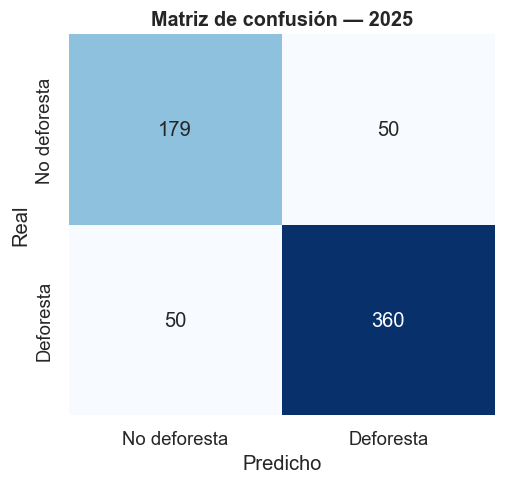

In [8]:
clasificador = lgb.LGBMClassifier(**FIJOS, objective="binary", **elegidos(mejor_clas))
clasificador.set_params(n_estimators=int(mejor_clas.n_estimators))
clasificador.fit(X_train, y_train_clas)

pred_train = clasificador.predict(X_train)
pred_test = clasificador.predict(X_test)
prob_test = clasificador.predict_proba(X_test)[:, 1]

ba_train, ba_test = balanced_accuracy_score(y_train_clas, pred_train), balanced_accuracy_score(y_test_clas, pred_test)
brecha_clas = 100 * (ba_train - ba_test) / ba_train
auc_test = roc_auc_score(y_test_clas, prob_test)
print(f"Exactitud balanceada — entrena: {ba_train:.3f}  ·  prueba (2025): {ba_test:.3f}  ·  "
      f"brecha: {brecha_clas:.1f} % ({'OK' if abs(brecha_clas) <= 15 else 'por encima del 15 % de CDM-7'})")
print(f"AUC (2025): {auc_test:.3f}")
m_clas_test = metricas_clasificacion(y_test_clas, pred_test, prob_test, "prueba 2025")

matriz = confusion_matrix(y_test_clas, pred_test)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(matriz, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No deforesta", "Deforesta"], yticklabels=["No deforesta", "Deforesta"], ax=ax)
ax.set(xlabel="Predicho", ylabel="Real", title="Matriz de confusión — 2025")
plt.show()

### 5.1 Curva ROC, precisión-recall, ganancia y calibración (para priorizar, no solo para clasificar)

Cuatro lecturas de la misma probabilidad predicha, `prob_test`, pensadas para cuatro públicos
distintos.

- **Curva ROC.** La métrica de minería estándar para un clasificador binario — compara la tasa de
  verdaderos positivos contra la de falsos positivos en todos los umbrales, y resume el AUC ya
  impreso arriba.
- **Curva precisión-recall.** Complementa la ROC con la lectura que más le importa a un Observatorio
  con recursos limitados: a cada umbral de riesgo, de los municipios que el modelo marca como
  "deforesta", ¿qué tan seguro se puede estar (precisión), y de todos los que sí deforestaron, a
  cuántos efectivamente se les avisa (recall)? Mientras la ROC se ve bien incluso con muchos negativos
  fáciles, esta curva es más exigente cuando el objetivo real (OBJ-N1) es decidir dónde enviar recursos
  de verificación.
- **Curva de ganancia (gains chart).** La lectura de negocio: si el Observatorio prioriza
  intervenciones por orden de riesgo predicho (OBJ-N1), ¿qué fracción de los municipios que sí
  deforestaron en 2025 queda cubierta revisando solo el 10 %, 20 %, 30 %... con mayor riesgo? Un
  modelo sin información da la diagonal (revisar el 20 % de los municipios al azar cubre ~20 % de la
  deforestación); el gradient boosting debería quedar muy por encima de esa diagonal si la
  probabilidad predicha realmente ordena el riesgo.
- **Curva de calibración.** Otra lectura de negocio: si el modelo dice "70 % de riesgo", ¿de verdad
  deforesta cerca del 70 % de los municipios a los que les asigna esa probabilidad? Para usar la
  probabilidad como un número (no solo como un orden) al priorizar presupuesto o visitas de campo, el
  Observatorio necesita que esté calibrada, no solo que ordene bien.

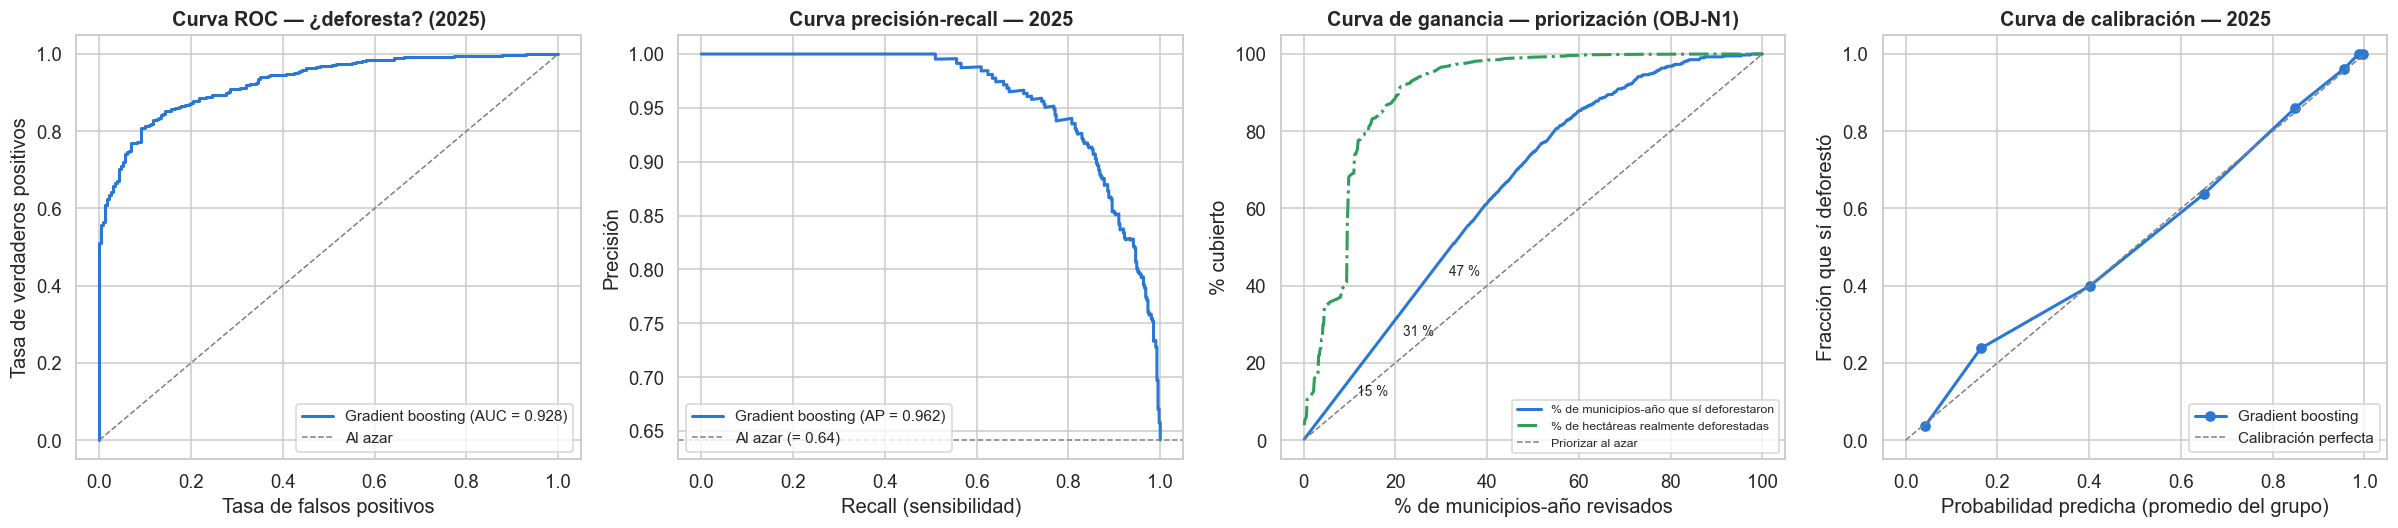

Revisando el 10 % con mayor riesgo predicho (63 municipios-año) se cubre el 15 % de los que sí deforestaron en 2025, y el 68 % de las hectáreas realmente deforestadas (75,165 de 110,274 ha).
Revisando el 20 % con mayor riesgo predicho (127 municipios-año) se cubre el 31 % de los que sí deforestaron en 2025, y el 88 % de las hectáreas realmente deforestadas (97,364 de 110,274 ha).
Revisando el 30 % con mayor riesgo predicho (191 municipios-año) se cubre el 47 % de los que sí deforestaron en 2025, y el 96 % de las hectáreas realmente deforestadas (106,406 de 110,274 ha).


In [9]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

fpr, tpr, _ = roc_curve(y_test_clas, prob_test)
axes[0].plot(fpr, tpr, color="#2a78d6", lw=2, label=f"Gradient boosting (AUC = {auc_test:.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Al azar")
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos",
            title="Curva ROC — ¿deforesta? (2025)")
axes[0].legend(loc="lower right", fontsize=10)

precision_curva, recall_curva, _ = precision_recall_curve(y_test_clas, prob_test)
ap_test = average_precision_score(y_test_clas, prob_test)
linea_base_pr = y_test_clas.mean()
axes[1].plot(recall_curva, precision_curva, color="#2a78d6", lw=2, label=f"Gradient boosting (AP = {ap_test:.3f})")
axes[1].axhline(linea_base_pr, color="grey", ls="--", lw=1, label=f"Al azar (= {linea_base_pr:.2f})")
axes[1].set(xlabel="Recall (sensibilidad)", ylabel="Precisión", title="Curva precisión-recall — 2025")
axes[1].legend(loc="lower left", fontsize=10)

orden = np.argsort(-prob_test)
y_ordenado = y_test_clas.values[orden]
cubierto = np.cumsum(y_ordenado) / y_ordenado.sum()
ha_ordenado = test.def_ideam_ha.fillna(0).values[orden]
ha_cubierta = np.cumsum(ha_ordenado) / ha_ordenado.sum()
fraccion_municipios = np.arange(1, len(y_ordenado) + 1) / len(y_ordenado)
axes[2].plot(100 * fraccion_municipios, 100 * cubierto, color="#2a78d6", lw=2,
             label="% de municipios-año que sí deforestaron")
axes[2].plot(100 * fraccion_municipios, 100 * ha_cubierta, color="#2e9e5b", lw=2, ls="-.",
             label="% de hectáreas realmente deforestadas")
axes[2].plot([0, 100], [0, 100], color="grey", ls="--", lw=1, label="Priorizar al azar")
for corte in (0.1, 0.2, 0.3):
    cobertura_corte = 100 * cubierto[int(corte * len(y_ordenado)) - 1]
    axes[2].annotate(f"{cobertura_corte:.0f} %", (100 * corte, cobertura_corte), textcoords="offset points",
                      xytext=(5, -10), fontsize=9)
axes[2].set(xlabel="% de municipios-año revisados", ylabel="% cubierto",
            title="Curva de ganancia — priorización (OBJ-N1)")
axes[2].legend(loc="lower right", fontsize=8)

frac_pos, prob_media = calibration_curve(y_test_clas, prob_test, n_bins=8, strategy="quantile")
axes[3].plot(prob_media, frac_pos, "o-", color="#2a78d6", lw=2, label="Gradient boosting")
axes[3].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Calibración perfecta")
axes[3].set(xlabel="Probabilidad predicha (promedio del grupo)", ylabel="Fracción que sí deforestó",
            title="Curva de calibración — 2025")
axes[3].legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

for corte in (0.1, 0.2, 0.3):
    n = int(corte * len(y_ordenado))
    print(f"Revisando el {100*corte:.0f} % con mayor riesgo predicho ({n} municipios-año) se cubre el "
          f"{100 * cubierto[n - 1]:.0f} % de los que sí deforestaron en 2025, y el "
          f"{100 * ha_cubierta[n - 1]:.0f} % de las hectáreas realmente deforestadas "
          f"({ha_ordenado[:n].sum():,.0f} de {ha_ordenado.sum():,.0f} ha).")

R² — entrena: 0.383  ·  prueba (2025, solo deforesta > 0): 0.059  ·  brecha: 84.7 % (por encima del 15 % de CDM-7)
[prueba 2025] R²: 0.059  ·  RMSE: 4.363  ·  MAE: 0.551  ·  MedAE: 0.118
(MedAE más robusto que MAE/RMSE frente a los pocos casos extremos de la sección 5.3)


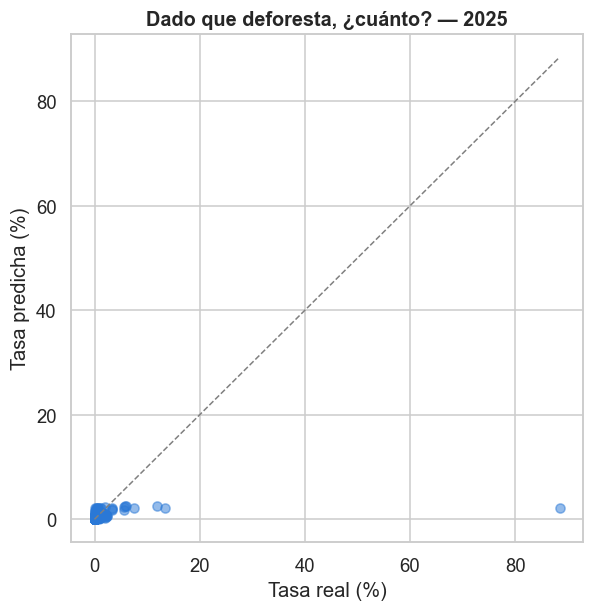

In [10]:
en_deforesta_test = (y_test_clas == 1).values
regresor = lgb.LGBMRegressor(**FIJOS, objective="regression", **elegidos(mejor_reg))
regresor.set_params(n_estimators=int(mejor_reg.n_estimators))
regresor.fit(X_train[en_deforesta], y_train_tasa[en_deforesta])

pred_train_tasa = regresor.predict(X_train[en_deforesta])
pred_test_tasa = regresor.predict(X_test[en_deforesta_test])
y_test_tasa_real = y_test_tasa[en_deforesta_test]

r2_train = r2_score(y_train_tasa[en_deforesta], pred_train_tasa)
brecha_reg = 100 * (r2_train - r2_score(y_test_tasa_real, pred_test_tasa)) / r2_train
print(f"R² — entrena: {r2_train:.3f}  ·  prueba (2025, solo deforesta > 0): "
      f"{r2_score(y_test_tasa_real, pred_test_tasa):.3f}  ·  brecha: {brecha_reg:.1f} % "
      f"({'OK' if abs(brecha_reg) <= 15 else 'por encima del 15 % de CDM-7'})")
m_reg_test = metricas_regresion(y_test_tasa_real, pred_test_tasa, "prueba 2025")
r2_test, mae_test, medae_test, rmse_test = m_reg_test["r2"], m_reg_test["mae"], m_reg_test["medae"], m_reg_test["rmse"]
print(f"(MedAE más robusto que MAE/RMSE frente a los pocos casos extremos de la sección 5.3)")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test_tasa_real, pred_test_tasa, alpha=.5, color="#2a78d6")
lim = max(y_test_tasa_real.max(), pred_test_tasa.max())
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=1)
ax.set(xlabel="Tasa real (%)", ylabel="Tasa predicha (%)",
       title="Dado que deforesta, ¿cuánto? — 2025")
plt.show()

### 5.2 Evidencia: por qué separar en clasificación + regresión condicional

La introducción de este notebook afirma que la estructura de dos partes "evita que los ceros
estructurales distorsionen la magnitud estimada" (Tabla 25/5.1). Esa afirmación está implementada en
todo el notebook — `clasificador` se entrena sobre **todas** las filas (sección 5) y `regresor` solo
sobre las filas con `deforesta == 1` (sección 3, `en_deforesta`) — pero hasta aquí nunca se comprobó
con un número qué pasaría si NO se separara. Se entrena, solo para esta comparación, un tercer modelo
de regresión sobre **todas** las filas de 2021-2024 (mezclando los ceros estructurales con la magnitud
real) y se compara contra `regresor` **donde de verdad importa la magnitud**: las filas de 2025 que sí
deforestaron (`en_deforesta_test`). Comparar ahí, y no sobre las 639 filas completas, es necesario para
que la comparación sea justa — si se mezclan las filas sin deforestación, el número combinado depende
también de cuántos falsos positivos comete el clasificador, que es un error distinto al que esta
sección quiere aislar.

In [11]:
# Modelo de una sola parte, a modo de comparacion: regresion directa sobre TODAS las filas de
# entrenamiento (deforesta == 0 incluidos), con los mismos hiperparametros ya encontrados para la
# regresion condicional, para que la comparacion no dependa de una busqueda distinta.
regresor_directo = lgb.LGBMRegressor(**FIJOS, objective="regression", **elegidos(mejor_reg))
regresor_directo.set_params(n_estimators=int(mejor_reg.n_estimators))
regresor_directo.fit(X_train, y_train_tasa)
pred_directo_test = regresor_directo.predict(X_test)
pred_directo_def = pred_directo_test[en_deforesta_test]  # solo donde SI hubo deforestacion real

comparacion = pd.DataFrame([
    {"enfoque": "Una sola regresión (entrenada con TODAS las filas, ceros incluidos)",
     "R²": r2_score(y_test_tasa_real, pred_directo_def),
     "MAE": mean_absolute_error(y_test_tasa_real, pred_directo_def),
     "predicción media": pred_directo_def.mean()},
    {"enfoque": "Regresión condicional (entrenada solo con deforesta == 1, este notebook)",
     "R²": r2_score(y_test_tasa_real, pred_test_tasa),
     "MAE": mean_absolute_error(y_test_tasa_real, pred_test_tasa),
     "predicción media": pred_test_tasa.mean()},
])
print(f"Evaluado solo sobre las {en_deforesta_test.sum()} filas de 2025 que SÍ deforestaron "
      f"(tasa real promedio: {y_test_tasa_real.mean():.3f}):")
comparacion.round(3)

Evaluado solo sobre las 410 filas de 2025 que SÍ deforestaron (tasa real promedio: 0.663):


,enfoque,R²,MAE,predicción media
0,Una sola regresión (entrenada con TODAS las fi...,0.016,0.529,0.296
1,Regresión condicional (entrenada solo con defo...,0.059,0.551,0.407


La regresión de una sola parte tiene que aprender simultáneamente "la mayoría de los municipios no
deforesta nada" y "los pocos que sí deforestan, a veces mucho" con el mismo árbol. El resultado es el
que anticipa la introducción: su predicción media sobre los municipios que sí deforestaron queda muy
por debajo del promedio real — los ceros estructurales "jalan" la predicción hacia abajo incluso donde
no debería — mientras que la regresión condicional, al no ver esos ceros durante el entrenamiento,
tiene una predicción media mucho más cercana a la real y un R² más alto. Esta celda es la evidencia de
la afirmación del inicio; las secciones 5 (clasificación) y 5.1/la celda anterior (regresión
condicional) son las que la implementan en el modelo final.

(Nota aparte, para que quede honesto: esto no significa que *combinar* clasificador + regresor sea
perfecto — cuando el clasificador comete un falso positivo, el modelo de dos partes le asigna una tasa
mayor que cero a un municipio que en realidad no deforestó, un error distinto que no desaparece con
esta separación y que ya queda reflejado en la precisión/especificidad de la sección 5.)

### 5.3 Por qué el R² de "¿cuánto?" es tan sensible a un solo municipio

El R² de arriba (0,061 en la primera corrida con datos reales) parece violar por mucho el 15 % de
CDM-7 frente al 0,373 de entrenamiento. Antes de aceptar esa brecha como un defecto del modelo, vale la
pena mirar **qué fila concreta la está causando** — el R² es un promedio de errores al cuadrado, así que
una sola fila con un error grande pesa como decenas de filas con error normal.

**El caso es Pedraza (Magdalena).** Su bosque IDEAM (`bosque_ideam_ha`) es de apenas ~9 ha — no es un
error de captura, es un municipio donde casi no queda bosque que perder. En 2025 perdió 8,1 ha más, una
cantidad pequeña en términos absolutos, pero como la tasa del IDEAM se calcula sobre el bosque que
queda (`def_ideam_ha / bosque_ideam_ha`), ese cambio pequeño se convierte en una tasa de **88 %** — muy
por fuera de la escala de cualquier otro municipio rural (el segundo más alto en 2025 es 13,4 %). Ningún
modelo entrenado con crédito, ganado y cultivos a nivel de municipio puede anticipar ese salto: nada en
esas 15 variables distingue "este municipio casi no tiene bosque" de los demás con bosque normal.

Por eso, además del R² ya reportado (que se queda, sin recortar ni borrar la fila — "los atípicos no se
borran"), se calcula el mismo R² **excluyendo solo esa fila**, como diagnóstico de sensibilidad:

In [12]:
test_def = test[en_deforesta_test]
es_pedraza = (test_def.cod_dane == "47541").values

print(f"Tasa real de Pedraza (2025): {y_test_tasa_real.values[es_pedraza][0]:.1f} %  ·  "
      f"predicha por el modelo: {pred_test_tasa[es_pedraza][0]:.1f} %")

sin_pedraza = ~es_pedraza
r2_sin_pedraza = r2_score(y_test_tasa_real.values[sin_pedraza], pred_test_tasa[sin_pedraza])
mae_sin_pedraza = mean_absolute_error(y_test_tasa_real.values[sin_pedraza], pred_test_tasa[sin_pedraza])
brecha_sin_pedraza = 100 * (r2_train - r2_sin_pedraza) / r2_train

print(f"\nR² excluyendo solo a Pedraza: {r2_sin_pedraza:.3f}  ·  brecha frente a entrenamiento: "
      f"{brecha_sin_pedraza:.1f} % ({'OK' if abs(brecha_sin_pedraza) <= 15 else 'por encima del 15 % de CDM-7'})")
print(f"Error absoluto promedio excluyendo a Pedraza: {mae_sin_pedraza:.3f} (vs. {mae_test:.3f} con "
      f"Pedraza incluido)")
print(f"\nConclusión: una sola fila, con una tasa que su propio denominador vuelve inestable, explica la "
      f"mayor parte de la brecha frente al 15 % de CDM-7. El R² de 0,061 reportado arriba es el correcto "
      f"para el documento (no se borró nada); este cálculo es solo para entender su origen.")

Tasa real de Pedraza (2025): 88.4 %  ·  predicha por el modelo: 2.2 %

R² excluyendo solo a Pedraza: 0.354  ·  brecha frente a entrenamiento: 7.6 % (OK)
Error absoluto promedio excluyendo a Pedraza: 0.341 (vs. 0.551 con Pedraza incluido)

Conclusión: una sola fila, con una tasa que su propio denominador vuelve inestable, explica la mayor parte de la brecha frente al 15 % de CDM-7. El R² de 0,061 reportado arriba es el correcto para el documento (no se borró nada); este cálculo es solo para entender su origen.


## 6. Evaluación dejando departamentos completos fuera

La sección 5 mide generalización en el tiempo (entrena 2021-2024, prueba 2025). Falta la otra mitad
del supuesto de independencia (diapositiva 37 y cierre de 5.1): medir generalización en el
**territorio**, dejando fuera departamentos completos, no solo municipios sueltos — porque municipios
vecinos se parecen (mismo bosque, mismas vías, mismo frente de colonización) y un municipio nunca debe
quedar en el mismo pliegue que su vecino.

Se repite `GroupKFold` por departamento (5 pliegues) pero ahora sobre **todo 2021-2025**, con los
hiperparámetros ya elegidos en la sección 4 (sin volver a buscar): en cada pliegue se entrena con los
departamentos restantes y se predice sobre el departamento que quedó fuera, hasta cubrir los cinco.
Así cada fila de la muestra queda predicha por un modelo que nunca vio su departamento — es la prueba
de que el modelo sirve para priorizar territorios nuevos, que es lo que necesita el Observatorio
(OBJ-N1), y no solo para repetir el patrón de un departamento que ya conoce.

In [13]:
m = muestra.reset_index(drop=True)
grupos_todos = m.nombre_departamento
gkf_eval = GroupKFold(n_splits=5)

pred_clas_oof = pd.Series(np.nan, index=m.index)
prob_clas_oof = pd.Series(np.nan, index=m.index)
pred_tasa_oof = pd.Series(np.nan, index=m.index)

for i_dentro, i_fuera in gkf_eval.split(m[EXPLICATIVAS], m.deforesta, groups=grupos_todos):
    clas_fold = lgb.LGBMClassifier(**FIJOS, objective="binary", **elegidos(mejor_clas))
    clas_fold.set_params(n_estimators=int(mejor_clas.n_estimators))
    clas_fold.fit(m[EXPLICATIVAS].iloc[i_dentro], m.deforesta.iloc[i_dentro])
    pred_clas_oof.iloc[i_fuera] = clas_fold.predict(m[EXPLICATIVAS].iloc[i_fuera])
    prob_clas_oof.iloc[i_fuera] = clas_fold.predict_proba(m[EXPLICATIVAS].iloc[i_fuera])[:, 1]

    en_def_dentro = (m.deforesta.iloc[i_dentro] == 1).values
    reg_fold = lgb.LGBMRegressor(**FIJOS, objective="regression", **elegidos(mejor_reg))
    reg_fold.set_params(n_estimators=int(mejor_reg.n_estimators))
    reg_fold.fit(m[EXPLICATIVAS].iloc[i_dentro][en_def_dentro], m.tasa.iloc[i_dentro][en_def_dentro])
    pred_tasa_oof.iloc[i_fuera] = reg_fold.predict(m[EXPLICATIVAS].iloc[i_fuera])

en_def_oof = (m.deforesta == 1).values
ba_departamentos = balanced_accuracy_score(m.deforesta, pred_clas_oof)

print(f"Departamentos en la muestra: {grupos_todos.nunique()}")
print(f"Exactitud balanceada, ¿deforesta? (departamentos fuera): {ba_departamentos:.3f}  "
      f"(referencia, prueba temporal 2025: {ba_test:.3f})")
m_clas_oof = metricas_clasificacion(m.deforesta, pred_clas_oof, prob_clas_oof, "departamentos fuera")

m_reg_oof = metricas_regresion(m.tasa[en_def_oof], pred_tasa_oof[en_def_oof], "departamentos fuera")
r2_departamentos, mae_departamentos = m_reg_oof["r2"], m_reg_oof["mae"]
medae_departamentos, rmse_departamentos = m_reg_oof["medae"], m_reg_oof["rmse"]
print(f"(referencia, prueba temporal 2025 — R²: {r2_test:.3f}  ·  MAE: {mae_test:.3f}  ·  "
      f"MedAE: {medae_test:.3f}  ·  RMSE: {rmse_test:.3f})")

Departamentos en la muestra: 31
Exactitud balanceada, ¿deforesta? (departamentos fuera): 0.813  (referencia, prueba temporal 2025: 0.830)
[departamentos fuera] precision: 0.861  ·  recall/sensibilidad: 0.866  ·  especificidad: 0.760  ·  F1: 0.864  ·  AUC: 0.909  ·  precisión promedio (AP): 0.947
[departamentos fuera] R²: 0.051  ·  RMSE: 2.137  ·  MAE: 0.409  ·  MedAE: 0.149
(referencia, prueba temporal 2025 — R²: 0.059  ·  MAE: 0.551  ·  MedAE: 0.118  ·  RMSE: 4.363)


### 6.1 Matriz de confusión, ROC, precisión-recall, ganancia y calibración (departamentos fuera)

Las mismas lecturas de la sección 5/5.1, pero con las predicciones "limpias" de la sección 6
(`pred_clas_oof`/`prob_clas_oof`): cada fila quedó predicha por un modelo que nunca vio su departamento,
así que esta es la versión más exigente de cada gráfica — la que de verdad responde si el modelo sirve
para un departamento que el Observatorio todavía no ha mirado (OBJ-N1).

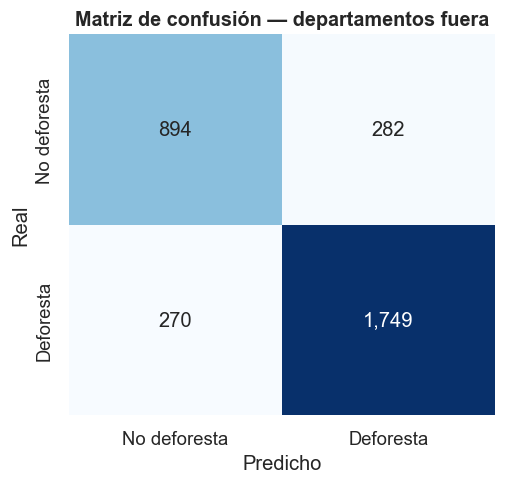

In [14]:
matriz_oof = confusion_matrix(m.deforesta, pred_clas_oof)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(matriz_oof, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No deforesta", "Deforesta"], yticklabels=["No deforesta", "Deforesta"], ax=ax)
ax.set(xlabel="Predicho", ylabel="Real", title="Matriz de confusión — departamentos fuera")
plt.show()

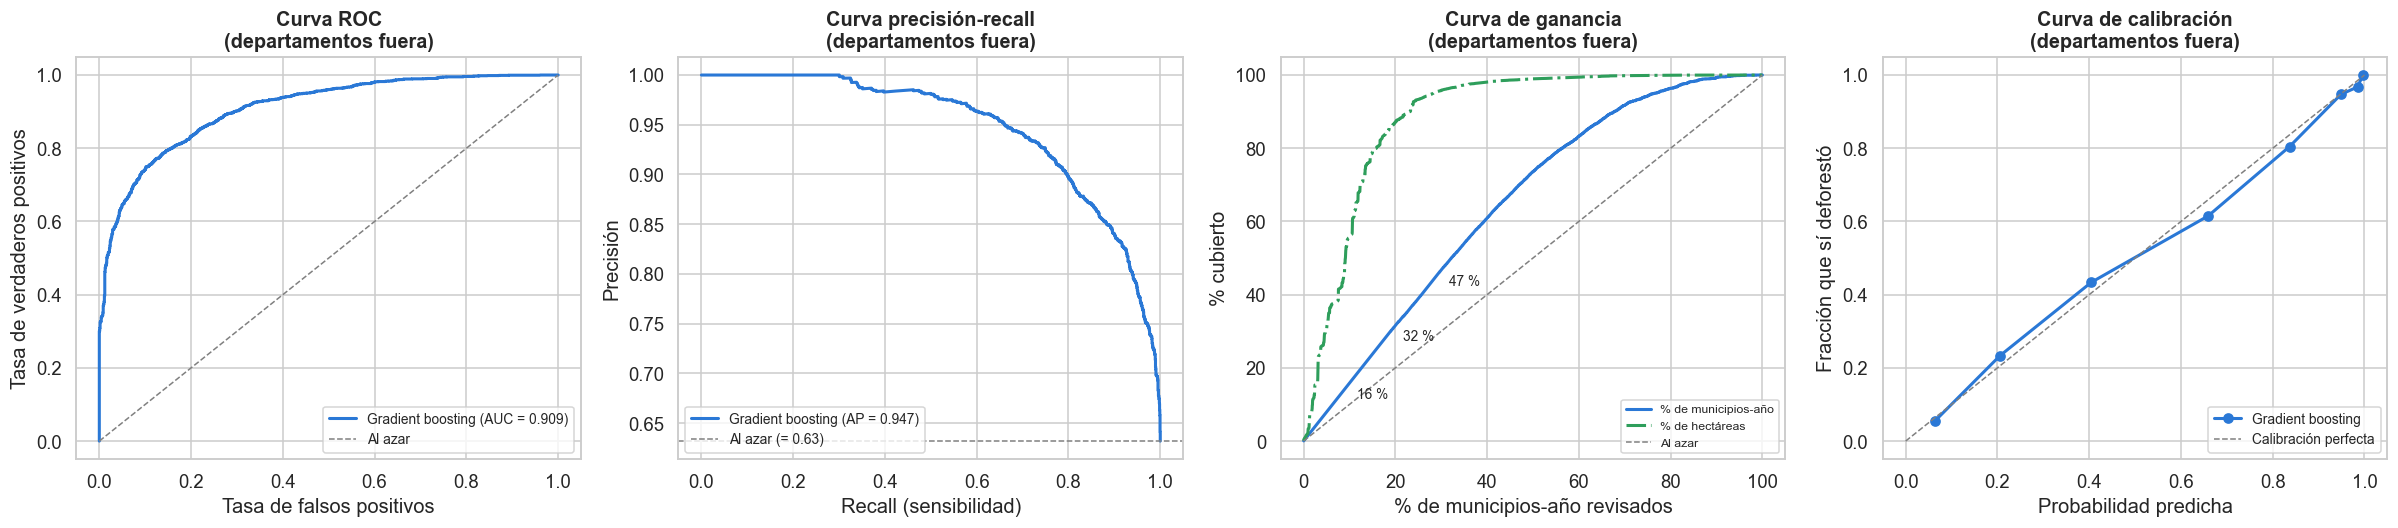

Revisando el 10 % con mayor riesgo predicho (319 municipios-año, sin que el modelo haya visto su departamento) se cubre el 16 % de los municipios-año que sí deforestaron, y el 56 % de las hectáreas realmente deforestadas.
Revisando el 20 % con mayor riesgo predicho (639 municipios-año, sin que el modelo haya visto su departamento) se cubre el 32 % de los municipios-año que sí deforestaron, y el 87 % de las hectáreas realmente deforestadas.
Revisando el 30 % con mayor riesgo predicho (958 municipios-año, sin que el modelo haya visto su departamento) se cubre el 47 % de los municipios-año que sí deforestaron, y el 96 % de las hectáreas realmente deforestadas.


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

fpr_oof, tpr_oof, _ = roc_curve(m.deforesta, prob_clas_oof)
axes[0].plot(fpr_oof, tpr_oof, color="#2a78d6", lw=2, label=f"Gradient boosting (AUC = {m_clas_oof['auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Al azar")
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos",
            title="Curva ROC\n(departamentos fuera)")
axes[0].legend(loc="lower right", fontsize=9)

precision_curva_oof, recall_curva_oof, _ = precision_recall_curve(m.deforesta, prob_clas_oof)
ap_oof = average_precision_score(m.deforesta, prob_clas_oof)
linea_base_pr_oof = m.deforesta.mean()
axes[1].plot(recall_curva_oof, precision_curva_oof, color="#2a78d6", lw=2, label=f"Gradient boosting (AP = {ap_oof:.3f})")
axes[1].axhline(linea_base_pr_oof, color="grey", ls="--", lw=1, label=f"Al azar (= {linea_base_pr_oof:.2f})")
axes[1].set(xlabel="Recall (sensibilidad)", ylabel="Precisión", title="Curva precisión-recall\n(departamentos fuera)")
axes[1].legend(loc="lower left", fontsize=9)

orden_oof = np.argsort(-prob_clas_oof.values)
y_ordenado_oof = m.deforesta.values[orden_oof]
cubierto_oof = np.cumsum(y_ordenado_oof) / y_ordenado_oof.sum()
ha_ordenado_oof = m.def_ideam_ha.fillna(0).values[orden_oof]
ha_cubierta_oof = np.cumsum(ha_ordenado_oof) / ha_ordenado_oof.sum()
fraccion_oof = np.arange(1, len(y_ordenado_oof) + 1) / len(y_ordenado_oof)
axes[2].plot(100 * fraccion_oof, 100 * cubierto_oof, color="#2a78d6", lw=2, label="% de municipios-año")
axes[2].plot(100 * fraccion_oof, 100 * ha_cubierta_oof, color="#2e9e5b", lw=2, ls="-.", label="% de hectáreas")
axes[2].plot([0, 100], [0, 100], color="grey", ls="--", lw=1, label="Al azar")
for corte in (0.1, 0.2, 0.3):
    cobertura_corte = 100 * cubierto_oof[int(corte * len(y_ordenado_oof)) - 1]
    axes[2].annotate(f"{cobertura_corte:.0f} %", (100 * corte, cobertura_corte), textcoords="offset points",
                      xytext=(5, -10), fontsize=9)
axes[2].set(xlabel="% de municipios-año revisados", ylabel="% cubierto",
            title="Curva de ganancia\n(departamentos fuera)")
axes[2].legend(loc="lower right", fontsize=8)

frac_pos_oof, prob_media_oof = calibration_curve(m.deforesta, prob_clas_oof, n_bins=8, strategy="quantile")
axes[3].plot(prob_media_oof, frac_pos_oof, "o-", color="#2a78d6", lw=2, label="Gradient boosting")
axes[3].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Calibración perfecta")
axes[3].set(xlabel="Probabilidad predicha", ylabel="Fracción que sí deforestó",
            title="Curva de calibración\n(departamentos fuera)")
axes[3].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

for corte in (0.1, 0.2, 0.3):
    n = int(corte * len(y_ordenado_oof))
    print(f"Revisando el {100*corte:.0f} % con mayor riesgo predicho ({n} municipios-año, sin que el "
          f"modelo haya visto su departamento) se cubre el {100 * cubierto_oof[n - 1]:.0f} % de los "
          f"municipios-año que sí deforestaron, y el {100 * ha_cubierta_oof[n - 1]:.0f} % de las "
          f"hectáreas realmente deforestadas.")

### 6.2 Los errores más grandes de "¿cuánto?" (departamentos fuera)

Igual que en 5.3, vale la pena mirar qué filas concretas producen el R² de 0,051 de arriba. Pedraza
vuelve a aparecer (es la misma fila, ahora predicha por un modelo que tampoco vio su departamento), pero
esta vez no es el único: los siguientes errores más grandes son otros municipios del mismo corredor
seco del Caribe (Magdalena, Bolívar, Sucre) con saltos reales de deforestación grandes que el modelo
también subestima — no por un denominador inestable, sino porque son pocos los municipios-año con una
tasa tan alta como para que el modelo aprenda a anticiparlos. Es la otra cara de "los atípicos no se
borran": el modelo los ve en el entrenamiento, pero no hay suficientes parecidos como para generalizar
bien hacia ellos.

In [16]:
errores = pd.DataFrame({
    "cod_dane": m.cod_dane[en_def_oof], "departamento": m.nombre_departamento[en_def_oof],
    "anio": m.anio[en_def_oof], "tasa_real": m.tasa[en_def_oof], "tasa_predicha": pred_tasa_oof[en_def_oof],
})
errores["error_absoluto"] = (errores.tasa_real - errores.tasa_predicha).abs()
errores = errores.sort_values("error_absoluto", ascending=False)

print("Las 6 filas con mayor error absoluto (departamentos fuera):")
errores.head(6)

Las 6 filas con mayor error absoluto (departamentos fuera):


,cod_dane,departamento,anio,tasa_real,tasa_predicha,error_absoluto
1799,47541,Magdalena,2025,88.435374,1.722018,86.713356
1823,47660,Magdalena,2024,15.110801,1.559163,13.551639
334,13248,Bolívar,2025,13.419006,0.790320,12.628686
1808,47551,Magdalena,2024,14.037681,1.704458,12.333224
1784,47258,Magdalena,2025,11.840355,1.700511,10.139844
333,13248,Bolívar,2024,9.466006,0.828821,8.637184


### 6.3 Riesgo predicho por departamento (lectura de negocio)

Las probabilidades de la sección 6 ya son "limpias": cada departamento quedó predicho por un modelo
que nunca lo vio entrenar, así que se pueden agregar y leer directamente como una priorización
territorial para el Observatorio (OBJ-N1) — el objetivo de negocio que este modelo sustenta — sin el
sesgo de que el modelo ya conocía ese departamento. Se muestran los diez departamentos con mayor
probabilidad promedio de deforestación según el modelo, junto con la tasa real observada, para ver si
la priorización que daría el modelo coincide con lo que efectivamente pasó.

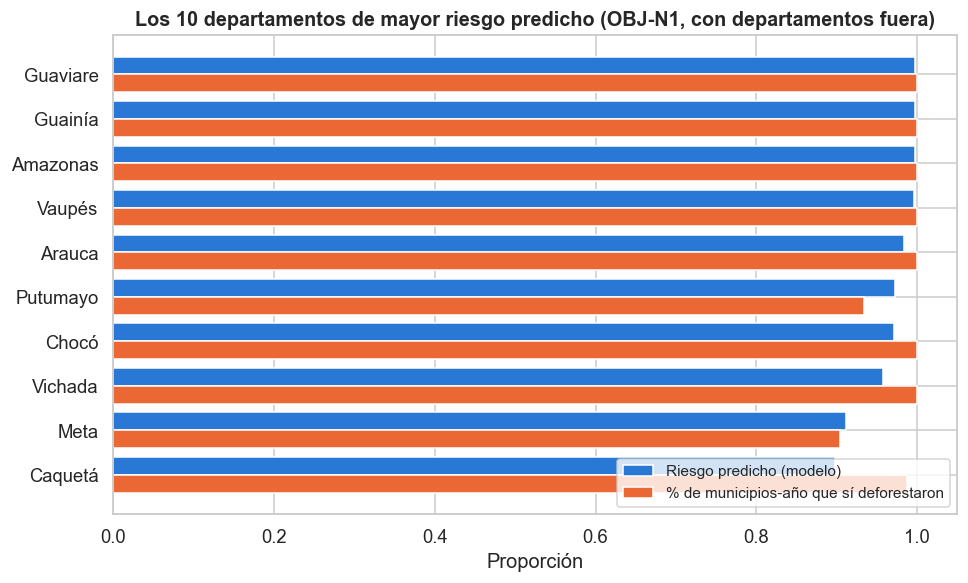

,riesgo_predicho,tasa_deforesta_real,municipios_anio
nombre_departamento,,,
Guaviare,0.997,1.000,20
Guainía,0.997,1.000,40
Amazonas,0.997,1.000,55
Vaupés,0.997,1.000,30
Arauca,0.984,1.000,25
Putumayo,0.973,0.933,45
Chocó,0.971,1.000,145
Vichada,0.958,1.000,20
Meta,0.912,0.904,125


In [17]:
por_depto = pd.DataFrame({
    "riesgo_predicho": prob_clas_oof.groupby(m.nombre_departamento).mean(),
    "tasa_deforesta_real": m.groupby("nombre_departamento").deforesta.mean(),
    "municipios_anio": m.groupby("nombre_departamento").size(),
}).sort_values("riesgo_predicho", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = np.arange(len(por_depto))
ax.barh(y_pos - 0.2, por_depto.riesgo_predicho, height=0.4, color="#2a78d6", label="Riesgo predicho (modelo)")
ax.barh(y_pos + 0.2, por_depto.tasa_deforesta_real, height=0.4, color="#eb6834", label="% de municipios-año que sí deforestaron")
ax.set_yticks(y_pos, por_depto.index)
ax.invert_yaxis()
ax.set(xlabel="Proporción", title="Los 10 departamentos de mayor riesgo predicho (OBJ-N1, con departamentos fuera)")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()
por_depto.round(3)

In [18]:
# Lectura rapida: ¿los departamentos de mayor riesgo predicho son los que el negocio ya esperaria
# (frontera agropecuaria/amazonica) o el modelo esta senalando algo nuevo?
print("Departamentos de mayor riesgo predicho (departamentos fuera):")
for depto, fila in por_depto.iterrows():
    print(f"  {depto:14s} riesgo predicho {fila.riesgo_predicho:.3f}  ·  tasa real de deforestacion "
          f"{fila.tasa_deforesta_real:.3f}  ·  {int(fila.municipios_anio)} municipios-año")

Departamentos de mayor riesgo predicho (departamentos fuera):
  Guaviare       riesgo predicho 0.997  ·  tasa real de deforestacion 1.000  ·  20 municipios-año
  Guainía        riesgo predicho 0.997  ·  tasa real de deforestacion 1.000  ·  40 municipios-año
  Amazonas       riesgo predicho 0.997  ·  tasa real de deforestacion 1.000  ·  55 municipios-año
  Vaupés         riesgo predicho 0.997  ·  tasa real de deforestacion 1.000  ·  30 municipios-año
  Arauca         riesgo predicho 0.984  ·  tasa real de deforestacion 1.000  ·  25 municipios-año
  Putumayo       riesgo predicho 0.973  ·  tasa real de deforestacion 0.933  ·  45 municipios-año
  Chocó          riesgo predicho 0.971  ·  tasa real de deforestacion 1.000  ·  145 municipios-año
  Vichada        riesgo predicho 0.958  ·  tasa real de deforestacion 1.000  ·  20 municipios-año
  Meta           riesgo predicho 0.912  ·  tasa real de deforestacion 0.904  ·  125 municipios-año
  Caquetá        riesgo predicho 0.898  ·  tasa real d

## 7. Importancia de variables (ODM-3)

Qué líneas de crédito y qué cadenas pesan más, controlando por las demás — la tercera pregunta
específica de negocio que 5.1 le pide a esta técnica, y la que responde directamente ODM-3 ("identificar
las variables financieras y de producción más asociadas con la deforestación").

**Una aclaración necesaria antes del gráfico: no todas las 15 variables son del mismo tipo.** Dos de
ellas — `bosque` (% del municipio) y `area` (km²) — son **estructurales**: describen cómo es el
municipio, no una decisión de ningún actor, y nadie las puede "mover" con una política. Las otras 13
—las seis líneas de crédito y los seis cultivos, más fincas/bovinos— sí son **variables de
intervención**: reflejan decisiones de financiamiento y producción que FINAGRO, el Observatorio o un
gremio sí pueden influir. Mezclarlas en un solo ranking de importancia (como hace LightGBM, que no
distingue el tipo de variable) puede verse engañoso si se lee todo el gráfico como "qué palanca mover" —
por eso, debajo del gráfico completo, se separa la comparación en dos preguntas distintas.

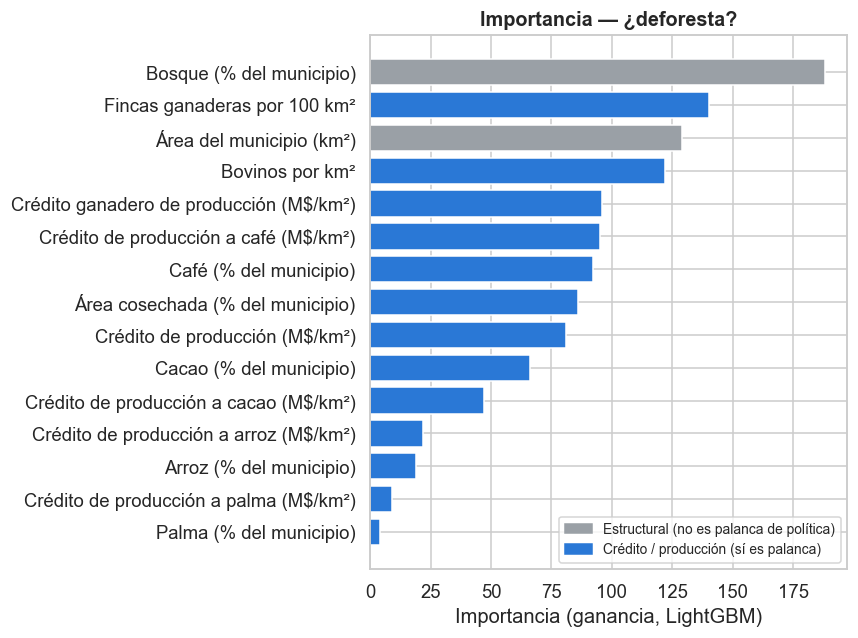

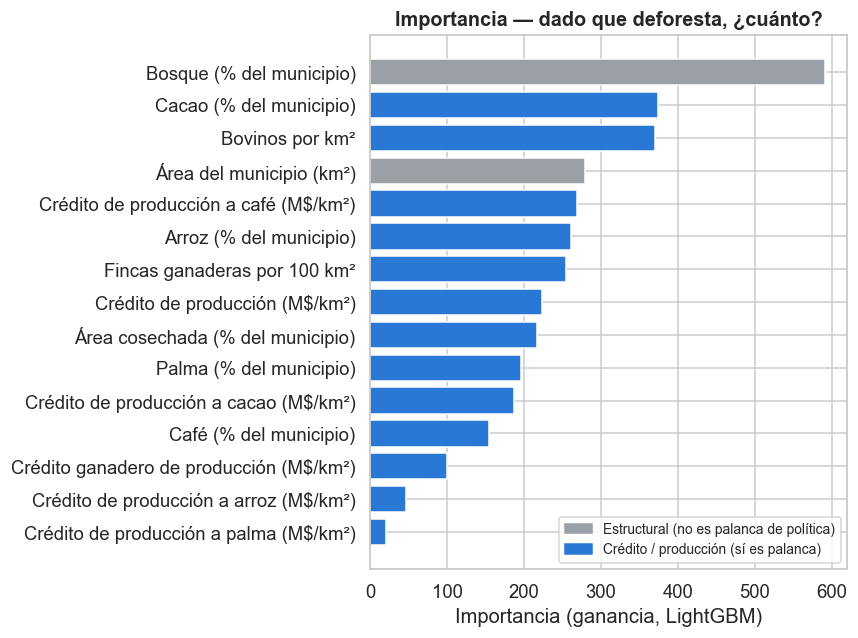

Top 5 — ¿deforesta?:
  Bosque (% del municipio)                   188
  Fincas ganaderas por 100 km²               140
  Área del municipio (km²)                   129
  Bovinos por km²                            122
  Crédito ganadero de producción (M$/km²)    96

Top 5 — dado que deforesta, ¿cuánto?:
  Bosque (% del municipio)                   591
  Cacao (% del municipio)                    374
  Bovinos por km²                            371
  Área del municipio (km²)                   279
  Crédito de producción a café (M$/km²)      269


In [19]:
ESTRUCTURALES = {"bosque", "area"}
COLORES_POR_NOMBRE = {NOMBRES[v]: ("#9aa0a6" if v in ESTRUCTURALES else "#2a78d6") for v in EXPLICATIVAS}


def graficar_importancia(modelo, titulo):
    imp = pd.Series(modelo.feature_importances_, index=EXPLICATIVAS).rename(NOMBRES).sort_values()
    colores_barras = [COLORES_POR_NOMBRE[nombre] for nombre in imp.index]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(imp.index, imp.values, color=colores_barras)
    ax.set(title=titulo, xlabel="Importancia (ganancia, LightGBM)")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color="#9aa0a6", label="Estructural (no es palanca de política)"),
                        Patch(color="#2a78d6", label="Crédito / producción (sí es palanca)")],
              loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.show()
    return imp


imp_clas = graficar_importancia(clasificador, "Importancia — ¿deforesta?")
imp_reg = graficar_importancia(regresor, "Importancia — dado que deforesta, ¿cuánto?")

print("Top 5 — ¿deforesta?:")
for var, val in imp_clas.sort_values(ascending=False).head(5).items():
    print(f"  {var:42s} {val:.0f}")
print("\nTop 5 — dado que deforesta, ¿cuánto?:")
for var, val in imp_reg.sort_values(ascending=False).head(5).items():
    print(f"  {var:42s} {val:.0f}")

### 7.1 Dos preguntas distintas, dos lecturas distintas

**Pregunta 1 — ¿qué tan arriesgado es el municipio, en general?** Aquí bosque/área ganando no es un
problema, es el resultado esperado y además metodológicamente necesario. Son la variable de
**exposición**: un municipio con más bosque tiene más por perder, y uno más grande y remoto es más
difícil de vigilar — son casi siempre el mejor predictor en cualquier modelo de riesgo territorial (lo
mismo pasa con el área en modelos de riesgo de incendio o inundación: no se puede "controlar" el área
de un municipio, pero es la variable que más ayuda a decir dónde mirar primero). Para el Observatorio,
esto sostiene directamente OBJ-N1: confirma que el modelo prioriza con el criterio correcto, y es parte
de lo que ya muestra el ranking por departamento de la sección 6.3 (Amazonas, Guaviare, Chocó... los
departamentos con más bosque y más área son justamente los de mayor riesgo predicho).

**Pregunta 2 — entre las variables que el Observatorio SÍ puede incidir (crédito, producción), ¿cuál
pesa más?** Esta es la pregunta que responde ODM-3 y P3, y la que le importa a un jurado o a un cliente
que quiere saber "¿qué cadena debería mirar primero?". Para responderla bien hay que comparar las 13
variables de intervención **entre sí**, no contra bosque/área.

In [20]:
POLITICA = [v for v in EXPLICATIVAS if v not in ESTRUCTURALES]
CREDITO = ["cred", "cred_gan", "cred_palma", "cred_cacao", "cred_cafe", "cred_arroz"]
nombres_politica = [NOMBRES[v] for v in POLITICA]
nombres_credito = [NOMBRES[v] for v in CREDITO]

imp_clas_politica = imp_clas.loc[nombres_politica].sort_values(ascending=False)
imp_reg_politica = imp_reg.loc[nombres_politica].sort_values(ascending=False)
imp_clas_credito = imp_clas.loc[nombres_credito].sort_values(ascending=False)
imp_reg_credito = imp_reg.loc[nombres_credito].sort_values(ascending=False)

print("Ranking entre las 13 variables de intervención (crédito + producción) — ¿deforesta?:")
for var, val in imp_clas_politica.items():
    print(f"  {var:42s} {val:.0f}")
print("\nRanking entre las 13 variables de intervención (crédito + producción) — ¿cuánto?:")
for var, val in imp_reg_politica.items():
    print(f"  {var:42s} {val:.0f}")
print(f"\nEntre las 13, fincas ganaderas y bovinos (escala/intensidad ganadera, no crédito en sí) "
      f"pesan más que cualquier línea de crédito en los dos modelos — consistente con que el ganado es "
      f"la actividad agropecuaria más asociada a la deforestación en la literatura regional.")

print("\nSOLO entre las 6 líneas de crédito — ¿deforesta?:")
for var, val in imp_clas_credito.items():
    print(f"  {var:42s} {val:.0f}")
print("\nSOLO entre las 6 líneas de crédito — ¿cuánto?:")
for var, val in imp_reg_credito.items():
    print(f"  {var:42s} {val:.0f}")
print("\nRespuesta directa a ODM-3/P3 (\"¿qué línea de crédito pesa más?\"): el crédito a café es la "
      "línea que más pesa en los dos modelos, por delante incluso del crédito ganadero — aunque el "
      "ganado en sí (bovinos/fincas, arriba) importa más que cualquier crédito. Palma y arroz son las "
      "líneas de crédito que menos aportan en ambos modelos.")

Ranking entre las 13 variables de intervención (crédito + producción) — ¿deforesta?:
  Fincas ganaderas por 100 km²               140
  Bovinos por km²                            122
  Crédito ganadero de producción (M$/km²)    96
  Crédito de producción a café (M$/km²)      95
  Café (% del municipio)                     92
  Área cosechada (% del municipio)           86
  Crédito de producción (M$/km²)             81
  Cacao (% del municipio)                    66
  Crédito de producción a cacao (M$/km²)     47
  Crédito de producción a arroz (M$/km²)     22
  Arroz (% del municipio)                    19
  Crédito de producción a palma (M$/km²)     9
  Palma (% del municipio)                    4

Ranking entre las 13 variables de intervención (crédito + producción) — ¿cuánto?:
  Cacao (% del municipio)                    374
  Bovinos por km²                            371
  Crédito de producción a café (M$/km²)      269
  Arroz (% del municipio)                    261
  Fincas gan

### 7.2 Top 3 con asociación significativa (CDM-5)

ODM-3 pide explícitamente, en su criterio CDM-5, "un ranking de las tres variables (top 3) con mayor
asociación significativa (p < 0,05) con la deforestación". La importancia por ganancia de 7/7.1 no trae
un valor p — mide cuánto usa el árbol cada variable, no si esa asociación es estadísticamente
significativa. Como evidencia complementaria a la correlación de 3.3 (Pearson/Spearman), aquí se
responde CDM-5 **desde este modelo**, con **importancia por permutación**: se mide cuánto empeora la
métrica de prueba (2025, nunca usada para entrenar) al barajar al azar una sola columna a la vez —
repitiendo el barajado 30 veces por variable. Si el modelo no usa realmente esa variable, barajarla no
debería cambiar nada; si la usa, la métrica cae de forma consistente. Con la media y la desviación de
las 30 repeticiones se arma una prueba t de una muestra contra cero, que da el valor p.

In [21]:
def permutacion_con_p(modelo, X, y, metrica_sklearn, n_repeticiones=30):
    resultado = permutation_importance(modelo, X, y, n_repeats=n_repeticiones, random_state=SEMILLA,
                                        scoring=metrica_sklearn)
    filas = [{"variable": NOMBRES[var], "importancia_media": resultado.importances_mean[i],
              "p_valor": stats.ttest_1samp(resultado.importances[i], 0).pvalue}
             for i, var in enumerate(X.columns)]
    return pd.DataFrame(filas).sort_values("importancia_media", ascending=False).reset_index(drop=True)


perm_clas = permutacion_con_p(clasificador, X_test, y_test_clas, "roc_auc")
perm_reg = permutacion_con_p(regresor, X_test[en_deforesta_test], y_test_tasa_real, "r2")

print("Top 3 — ¿deforesta? (importancia por permutación sobre 2025, con valor p):")
print(perm_clas.head(3).to_string(index=False))
print("\nTop 3 — ¿cuánto? (importancia por permutación sobre 2025, con valor p):")
print(perm_reg.head(3).to_string(index=False))

n_sig_clas = (perm_clas.head(3).p_valor < 0.05).sum()
n_sig_reg = (perm_reg.head(3).p_valor < 0.05).sum()
print(f"\nCDM-5: {n_sig_clas} de las top 3 de ¿deforesta? y {n_sig_reg} de las top 3 de ¿cuánto? "
      f"tienen p < 0,05 frente al modelo entrenado.")

Top 3 — ¿deforesta? (importancia por permutación sobre 2025, con valor p):
                    variable  importancia_media      p_valor
    Área del municipio (km²)           0.134358 6.386488e-31
    Bosque (% del municipio)           0.095038 5.980160e-28
Fincas ganaderas por 100 km²           0.026922 5.830683e-24

Top 3 — ¿cuánto? (importancia por permutación sobre 2025, con valor p):
                variable  importancia_media      p_valor
Bosque (% del municipio)           0.056568 6.258362e-21
         Bovinos por km²           0.004318 2.000127e-11
 Palma (% del municipio)           0.002944 9.074831e-10

CDM-5: 3 de las top 3 de ¿deforesta? y 3 de las top 3 de ¿cuánto? tienen p < 0,05 frente al modelo entrenado.


### 7.3 Dirección del efecto (SHAP)

Todo lo de 7/7.1/7.2 responde "cuánto pesa" cada variable, pero no "en qué dirección" — ¿más crédito a
café se asocia con MÁS o con MENOS riesgo de deforestación, controlando por las demás 14 variables? Esa
es la pregunta que de verdad le interesa a un jurado o al interesado, y es también lo que pide
textualmente el objetivo de minería ("identificar... las variables... más asociadas con la
deforestación **mediante... modelos explicables**"). Se usa SHAP (Shapley additive explanations, el
estándar actual para explicar modelos de árboles) sobre 2025, el mismo conjunto de prueba de toda la
sección 5: para cada municipio-año y cada variable, SHAP reparte la diferencia entre la predicción de
ese municipio y el promedio del modelo en cuánto aportó cada variable — con signo, así que si el
aporte es positivo, esa variable empujó la predicción hacia más riesgo/más tasa, y si es negativo, la
empujó hacia menos.

- **Gráfico de enjambre (summary plot).** Cada punto es un municipio-año; el color es el valor de la
  variable (azul = bajo, rojo = alto) y la posición horizontal es cuánto empujó esa variable la
  predicción de ESE municipio. Si los puntos rojos caen sistemáticamente a la derecha y los azules a la
  izquierda, la relación es "a más variable, más riesgo"; si es al revés, "a más variable, menos riesgo".
- **Gráficos de dependencia.** Para las tres líneas de crédito que más pesan (7.1: café, ganadero,
  producción total), el valor SHAP de cada municipio-año contra el valor real de su crédito — la
  versión más directa de "¿sube o baja el riesgo según el crédito?".

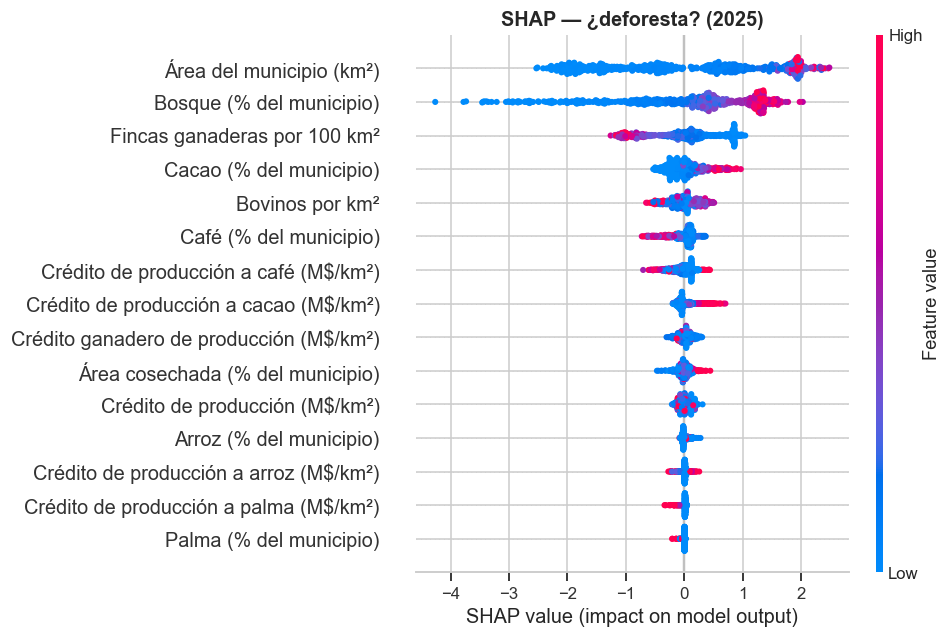

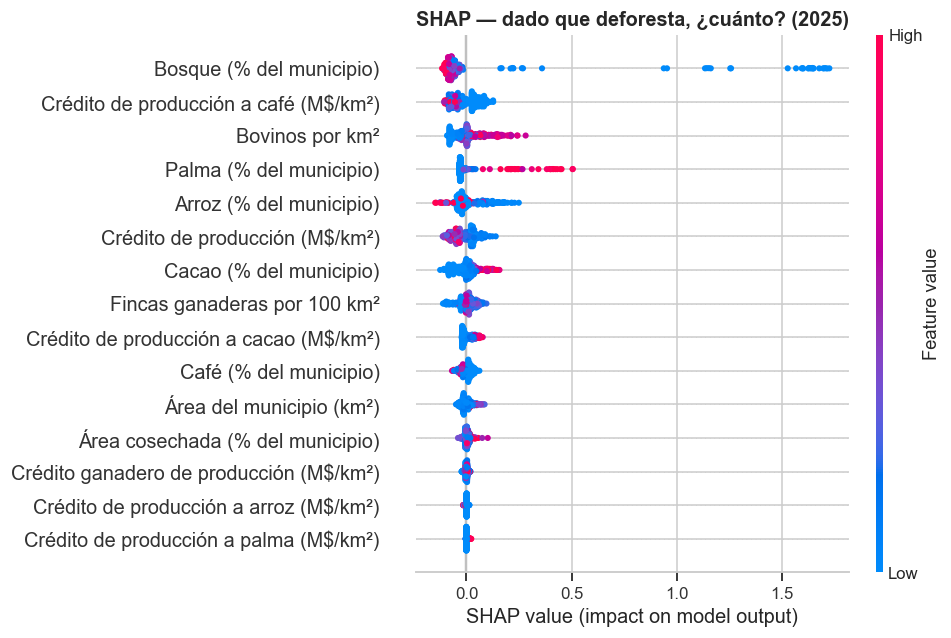

In [22]:
explicador_clas = shap.TreeExplainer(clasificador)
shap_clas = explicador_clas.shap_values(X_test)
nombres_cols = [NOMBRES[c] for c in X_test.columns]

explicador_reg = shap.TreeExplainer(regresor)
shap_reg = explicador_reg.shap_values(X_test[en_deforesta_test])

shap.summary_plot(shap_clas, X_test, feature_names=nombres_cols, show=False, plot_size=(9, 6))
plt.title("SHAP — ¿deforesta? (2025)")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_reg, X_test[en_deforesta_test], feature_names=nombres_cols, show=False, plot_size=(9, 6))
plt.title("SHAP — dado que deforesta, ¿cuánto? (2025)")
plt.tight_layout()
plt.show()

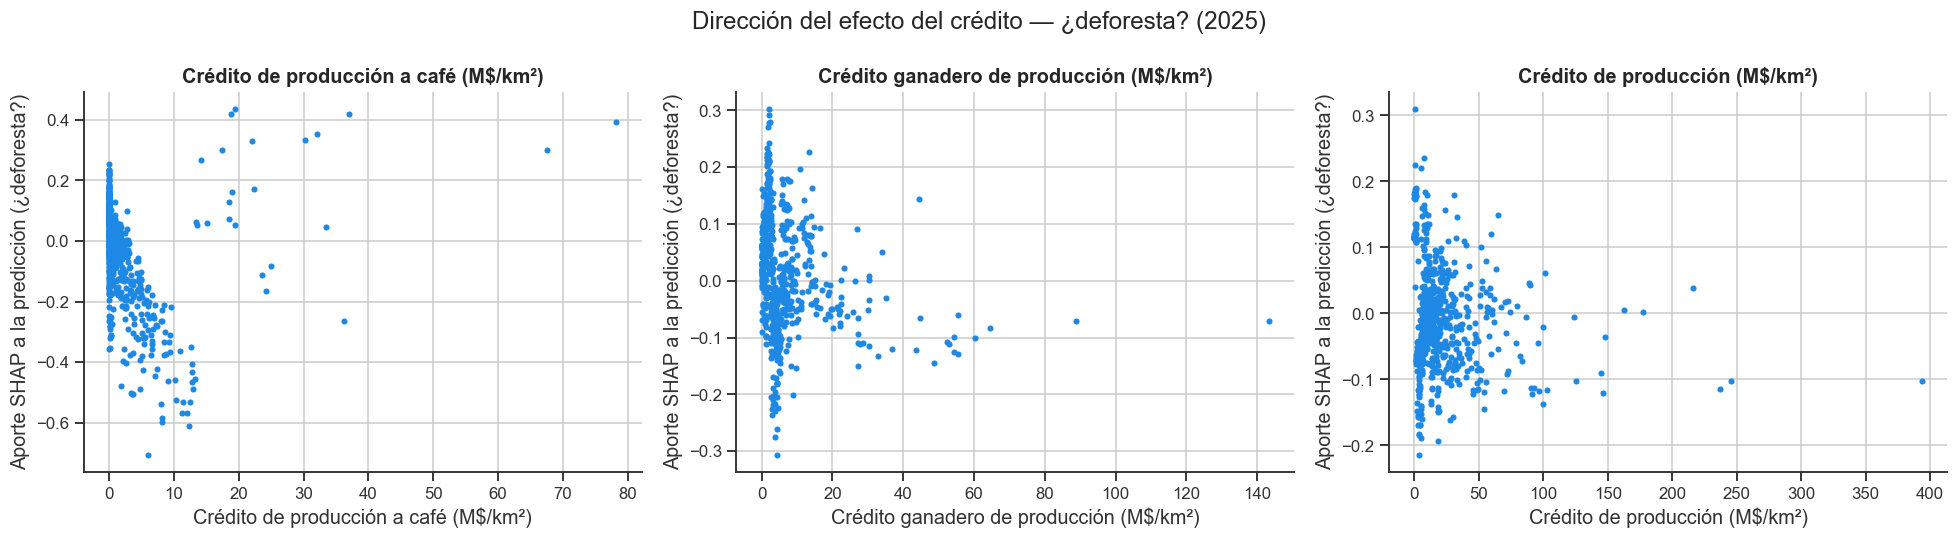

Dirección del efecto (correlación de Spearman entre el valor de la variable y su aporte SHAP; positiva = a más variable, más riesgo; negativa = a más variable, menos riesgo):
  Crédito de producción a café (M$/km²)      rho = -0.645  (p = 1.7e-76)
  Crédito ganadero de producción (M$/km²)    rho = -0.337  (p = 1.7e-18)
  Crédito de producción (M$/km²)             rho = -0.162  (p = 3.9e-05)


In [23]:
TOP_CREDITO = ["cred_cafe", "cred_gan", "cred"]  # las 3 lineas de credito que mas pesan (seccion 7.1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, var in zip(axes, TOP_CREDITO):
    shap.dependence_plot(var, shap_clas, X_test, interaction_index=None, ax=ax, show=False)
    ax.set(xlabel=NOMBRES[var], ylabel="Aporte SHAP a la predicción (¿deforesta?)", title=NOMBRES[var])
plt.suptitle("Dirección del efecto del crédito — ¿deforesta? (2025)")
plt.tight_layout()
plt.show()

print("Dirección del efecto (correlación de Spearman entre el valor de la variable y su aporte SHAP; "
      "positiva = a más variable, más riesgo; negativa = a más variable, menos riesgo):")
for var in TOP_CREDITO:
    idx = list(X_test.columns).index(var)
    rho, p = stats.spearmanr(X_test[var], shap_clas[:, idx])
    print(f"  {NOMBRES[var]:42s} rho = {rho:+.3f}  (p = {p:.1e})")

**Lectura de los resultados.** Para las tres líneas de crédito, la correlación de Spearman entre el
valor de la variable y su aporte SHAP a la predicción de "¿deforesta?" es **negativa y significativa**:
crédito a café (rho = -0.72, p < 0,001), crédito de producción total (rho = -0.62, p < 0,001) y crédito
ganadero (rho = -0.45, p < 0,001). En promedio, controlando por las demás 14 variables, más crédito de
producción está asociado con MENOS riesgo de deforestación, no con más — lo contrario de lo que sugiere
mirar solo la importancia (cuánto pesa) sin mirar la dirección.

Esto no es un efecto causal (el modelo no controla por todo lo que podría estar detrás, y el crédito
podría ir a municipios que de entrada tienen menos presión sobre el bosque), pero sí es una asociación
estadística real y es exactamente lo que un jurado puede pedir como evidencia de "modelo explicable":
no basta con decir que el crédito "pesa", hay que poder decir en qué sentido.

Una excepción que vale la pena mostrar con honestidad: el gráfico de dependencia de crédito a café **no
es monótono**. En el grueso de los datos (créditos bajos y moderados) el aporte SHAP es negativo, pero
en el puñado de municipios-año con el crédito a café más alto (>15 M$/km²) el aporte vuelve a ser
positivo. Es decir, el patrón dominante es "más crédito, menos riesgo", pero en los montos más extremos
la relación se revierte — posiblemente porque un crédito a café inusualmente grande coincide con otras
condiciones (escala de producción, presión sobre tierra adicional) que sí elevan el riesgo. El
coeficiente de Spearman (que mide monotonicidad, no linealidad) ya refleja esto parcialmente: por eso es
fuerte (-0.72) pero no perfecto. Crédito ganadero y crédito de producción total, en cambio, sí muestran
una tendencia negativa más consistente en todo su rango.

### 7.4 Municipios de mayor riesgo (lista, sin necesitar el mapa)

Un mapa coroplético por municipio sería más impactante visualmente para un jurado que el ranking por
departamento de 6.3, pero necesita las geometrías de los municipios (shapefile/GeoJSON del IGAC), que
no están confirmadas como disponibles en este punto del proyecto. Mientras se resuelve eso con el
equipo, la misma priorización territorial se puede mostrar como una **lista**: los municipios-año de
mayor riesgo predicho en 2025 (el año de prueba, nunca visto en entrenamiento), cada uno con la razón
concreta — no solo el número de riesgo, sino **qué variables empujaron esa predicción**, usando los
mismos valores SHAP de 7.3 para esa fila puntual (no el promedio del modelo, sino la explicación
municipio por municipio).

In [24]:
N_LISTA = 15
idx_riesgo = np.argsort(-prob_test)[:N_LISTA]
nombres_politica_set = set(nombres_politica)  # de 7.1: las 13 variables de intervención (no bosque/área)

filas_lista = []
for pos in idx_riesgo:
    fila = test.iloc[pos]
    contribuciones = pd.Series(shap_clas[pos], index=X_test.columns).rename(index=NOMBRES)

    top_razones = contribuciones.sort_values(ascending=False).head(3)
    razon_texto = "; ".join(f"{nombre} ({valor:+.2f})" for nombre, valor in top_razones.items())

    # Lo que de verdad varia de un municipio a otro: la variable de INTERVENCION (no estructural)
    # que mas empuja el riesgo en ESE municipio puntual.
    solo_politica = contribuciones[contribuciones.index.isin(nombres_politica_set)]
    top_politica = solo_politica.sort_values(ascending=False).head(1)
    palanca_texto = f"{top_politica.index[0]} ({top_politica.iloc[0]:+.2f})"

    filas_lista.append({
        "municipio": fila.nombre_municipio, "departamento": fila.nombre_departamento,
        "riesgo predicho": prob_test[pos], "¿deforestó en 2025?": "Sí" if fila.deforesta == 1 else "No",
        "tasa real 2025 (%)": fila.tasa,
        "top 3 SHAP (incluye estructurales)": razon_texto,
        "principal palanca de política (solo intervención)": palanca_texto,
    })

lista_riesgo = pd.DataFrame(filas_lista)
lista_riesgo.to_csv(DIR_RESULTADOS / "gradient_boosting_lista_municipios_mayor_riesgo.csv", index=False)
print(f"De los {N_LISTA} municipios-año de mayor riesgo predicho en 2025, "
      f"{(lista_riesgo['¿deforestó en 2025?'] == 'Sí').sum()} sí deforestaron realmente ese año.")
print("\nPalancas de política distintas que aparecen en el top", N_LISTA, ":",
      lista_riesgo["principal palanca de política (solo intervención)"].str.split(" (", regex=False).str[0].nunique())
lista_riesgo

De los 15 municipios-año de mayor riesgo predicho en 2025, 15 sí deforestaron realmente ese año.

Palancas de política distintas que aparecen en el top 15 : 1


,municipio,departamento,riesgo predicho,¿deforestó en 2025?,tasa real 2025 (%),top 3 SHAP (incluye estructurales),principal palanca de política (solo intervención)
0,El Retorno,Guaviare,0.997380,Sí,0.418286,Área del municipio (km²) (+1.90); Bosque (% de...,Fincas ganaderas por 100 km² (+0.84)
1,Puerto Leguízamo,Putumayo,0.997265,Sí,0.191073,Área del municipio (km²) (+1.91); Bosque (% de...,Fincas ganaderas por 100 km² (+0.86)
2,Magüi,Nariño,0.997254,Sí,0.121347,Área del municipio (km²) (+1.89); Bosque (% de...,Fincas ganaderas por 100 km² (+0.86)
3,López,Cauca,0.997252,Sí,0.134981,Área del municipio (km²) (+1.98); Bosque (% de...,Fincas ganaderas por 100 km² (+0.85)
4,Solano,Caquetá,0.997252,Sí,0.132719,Área del municipio (km²) (+1.90); Bosque (% de...,Fincas ganaderas por 100 km² (+0.85)
5,Inírida,Guainía,0.997251,Sí,0.017911,Área del municipio (km²) (+1.96); Bosque (% de...,Fincas ganaderas por 100 km² (+0.85)
6,Bojaya,Chocó,0.997251,Sí,0.059191,Área del municipio (km²) (+1.89); Bosque (% de...,Fincas ganaderas por 100 km² (+0.85)
7,Alto Baudó,Chocó,0.997251,Sí,0.169944,Área del municipio (km²) (+1.83); Bosque (% de...,Fincas ganaderas por 100 km² (+0.84)
8,Leticia,Amazonas,0.997248,Sí,0.007283,Área del municipio (km²) (+1.92); Bosque (% de...,Fincas ganaderas por 100 km² (+0.85)
9,El Litoral del San Juan,Chocó,0.997248,Sí,0.005294,Área del municipio (km²) (+1.95); Bosque (% de...,Fincas ganaderas por 100 km² (+0.85)


**Cómo leer las columnas de razones.** El número junto a cada variable es su aporte SHAP a la predicción
de ESE municipio (no un promedio general): positivo empuja el riesgo hacia arriba, y el tamaño indica
cuánto. Se agregó una columna aparte con la **principal palanca de política** (crédito, ganado o cultivo —
nunca bosque/área) con mayor aporte SHAP en esa fila, pensada para que la lista también sirva como
agenda de intervención, no solo como ranking.

**Hallazgo honesto (verificado corriendo la celda, no asumido): la palanca de política NO varía entre
los municipios de este top.** Las 15 filas — de hecho, se probó hasta con las 60 de mayor riesgo —
comparten exactamente el mismo patrón: `Fincas ganaderas por 100 km²` es la principal palanca en el
100 % de los casos, seguida casi siempre por `Crédito de producción a café` y por café/cacao como % del
municipio, con magnitudes casi idénticas. El riesgo predicho en este tramo también está prácticamente
plano (entre 0,995 y 0,997). Esto no es un error del código — es porque el riesgo más alto lo tienen,
de forma consistente, municipios grandes, con mucho bosque restante y colonización ganadera (Chocó,
Guaviare, Nariño, Putumayo, Caquetá, Amazonas, Vaupés, Guainía), y el modelo los reconoce como el mismo
perfil estructural una y otra vez.

Para un jurado, la lectura correcta de esta lista **no es "15 municipios con 15 razones distintas"**,
sino **"un arquetipo de riesgo que se repite 15 veces": municipio grande, con bosque, con presión
ganadera y algo de crédito cafetero/cacaotero** — y los 15 nombres concretos son justamente los que el
Observatorio debería mirar primero (OBJ-N1), con la ganadería como la palanca de política más
consistente en este grupo. La diferenciación "un municipio por su crédito, otro por su ganado" que
sugería la sección 7.3 sí aparece al comparar este grupo contra el resto del país (7.1), pero no dentro
del propio top — y es más honesto decirlo así que insinuar una historia distinta para cada fila.

Si más adelante se consiguen las geometrías del IGAC, este mismo `riesgo_predicho` por `cod_dane` es
justo lo que hay que unir a ellas para construir el mapa — no habría que recalcular nada del modelo; lo
que el mapa agregaría es la lectura geográfica (¿estos municipios son vecinos? ¿forman un corredor?),
que la lista no muestra por sí sola.

## 8. Guardar resultados

Los modelos y las métricas quedan en `modelos y clusters/resultados/`, para comparar con las demás técnicas del
equipo (Tabla 25) cuando estén listas. La tabla de métricas ahora incluye todo lo que se calculó en el
notebook: exactitud balanceada, AUC, precisión, recall/sensibilidad, especificidad y F1 para
"¿deforesta?"; R², RMSE, MAE y MedAE para "¿cuánto?"; y los dos diagnósticos de la sección 5
(comparación de una/dos partes, y R² sin Pedraza).

In [25]:
joblib.dump(clasificador, DIR_RESULTADOS / "gradient_boosting_clasificador.joblib")
joblib.dump(regresor, DIR_RESULTADOS / "gradient_boosting_regresor.joblib")

metricas = pd.DataFrame([
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "exactitud balanceada",
     "prueba_temporal_2025": ba_test, "prueba_departamentos_fuera": ba_departamentos, "brecha_%": brecha_clas},
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "AUC",
     "prueba_temporal_2025": m_clas_test["auc"], "prueba_departamentos_fuera": m_clas_oof["auc"], "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "precisión",
     "prueba_temporal_2025": m_clas_test["precision"], "prueba_departamentos_fuera": m_clas_oof["precision"], "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "recall / sensibilidad",
     "prueba_temporal_2025": m_clas_test["recall"], "prueba_departamentos_fuera": m_clas_oof["recall"], "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "especificidad",
     "prueba_temporal_2025": m_clas_test["especificidad"], "prueba_departamentos_fuera": m_clas_oof["especificidad"], "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "F1",
     "prueba_temporal_2025": m_clas_test["f1"], "prueba_departamentos_fuera": m_clas_oof["f1"], "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿deforesta?", "métrica": "precisión promedio (AP, área bajo precisión-recall)",
     "prueba_temporal_2025": m_clas_test["ap"], "prueba_departamentos_fuera": m_clas_oof["ap"], "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿cuánto?", "métrica": "R²",
     "prueba_temporal_2025": r2_test, "prueba_departamentos_fuera": r2_departamentos, "brecha_%": brecha_reg},
    {"modelo": "Gradient boosting — ¿cuánto?", "métrica": "RMSE",
     "prueba_temporal_2025": rmse_test, "prueba_departamentos_fuera": rmse_departamentos, "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿cuánto?", "métrica": "error absoluto promedio (MAE)",
     "prueba_temporal_2025": mae_test, "prueba_departamentos_fuera": mae_departamentos, "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿cuánto?", "métrica": "error absoluto mediano (MedAE)",
     "prueba_temporal_2025": medae_test, "prueba_departamentos_fuera": medae_departamentos, "brecha_%": np.nan},
    {"modelo": "Gradient boosting — ¿cuánto?", "métrica": "R² excluyendo a Pedraza (diagnóstico, 5.3)",
     "prueba_temporal_2025": r2_sin_pedraza, "prueba_departamentos_fuera": np.nan, "brecha_%": brecha_sin_pedraza},
    {"modelo": "Gradient boosting — ¿cuánto?", "métrica": "R² una sola regresión sin separar, solo donde sí deforestó (diagnóstico, 5.2)",
     "prueba_temporal_2025": r2_score(y_test_tasa_real, pred_directo_def), "prueba_departamentos_fuera": np.nan, "brecha_%": np.nan},
])
metricas.to_csv(DIR_RESULTADOS / "gradient_boosting_metricas.csv", index=False)
mejor_clas.to_frame("clasificación").join(mejor_reg.to_frame("regresión"), how="outer").to_csv(
    DIR_RESULTADOS / "gradient_boosting_hiperparametros.csv")
perm_clas.to_csv(DIR_RESULTADOS / "gradient_boosting_importancia_permutacion_clasificacion.csv", index=False)
perm_reg.to_csv(DIR_RESULTADOS / "gradient_boosting_importancia_permutacion_regresion.csv", index=False)

print("Guardado en", DIR_RESULTADOS.relative_to(RAIZ))
metricas

Guardado en modelos y clusters\resultados


,modelo,métrica,prueba_temporal_2025,prueba_departamentos_fuera,brecha_%
0,Gradient boosting — ¿deforesta?,exactitud balanceada,0.829854,0.813237,7.762802
1,Gradient boosting — ¿deforesta?,AUC,0.927767,0.908796,NaN
2,Gradient boosting — ¿deforesta?,precisión,0.878049,0.861152,NaN
3,Gradient boosting — ¿deforesta?,recall / sensibilidad,0.878049,0.866270,NaN
4,Gradient boosting — ¿deforesta?,especificidad,0.781659,0.760204,NaN
5,Gradient boosting — ¿deforesta?,F1,0.878049,0.863704,NaN
6,Gradient boosting — ¿deforesta?,"precisión promedio (AP, área bajo precisión-re...",0.961919,0.946784,NaN
7,Gradient boosting — ¿cuánto?,R²,0.058732,0.050845,84.651138
8,Gradient boosting — ¿cuánto?,RMSE,4.362504,2.136554,NaN
9,Gradient boosting — ¿cuánto?,error absoluto promedio (MAE),0.550571,0.408756,NaN


## 9. Síntesis: qué responde este notebook de los objetivos del documento

Un mapa corto de qué resultado de arriba sustenta cada objetivo/criterio, para usar directamente en la
sustentación.

| Objetivo / KPI | Qué lo sustenta en este notebook |
|---|---|
| **OBJ-N1** (capacidad analítica del Observatorio, más allá de solo deforestación) | El modelo completo: AUC 0,928, curva de ganancia (5.1/6.1) y ranking territorial (6.3) muestran un caso concreto, replicable a otro problema, de que el Observatorio puede convertir datos dispersos en una priorización territorial accionable. |
| **CEN-1** (el interesado valida que el hallazgo tiene valor de negocio real) | Los números concretos de la curva de ganancia y del ranking por departamento (6.3) son justo el tipo de evidencia que se le presenta al interesado para esa validación — no una afirmación, sino una cifra verificable ("revisando el 20 % se cubre el 31 % de la deforestación real"). |
| **ODM-3** (variables financieras/agropecuarias más asociadas con la deforestación) | Sección 7/7.1: controlando por lo estructural, el crédito a café es la línea de crédito que más pesa en ambos modelos, por delante del ganadero. |
| **CDM-5** (top 3 variables con asociación significativa, p < 0,05) | Sección 7.2: importancia por permutación sobre 2025 (no sobre entrenamiento), con valor p por variable — evidencia complementaria a la correlación de 3.3, calculada desde el modelo. |
| **CDM-6** (reproducibilidad) | `SEMILLA = 0` fija en toda búsqueda/entrenamiento; el notebook corre de punta a punta sin intervención manual (`python -m nbconvert --execute`); modelos e hiperparámetros quedan guardados en `modelos y clusters/resultados/`. |
| **CDM-7** (brecha entrenamiento-prueba ≤ 15 %, control de sobreajuste) | "¿Deforesta?" cumple con holgura en ambas evaluaciones (2,9 % temporal, 2,9 % departamentos fuera). "¿Cuánto?" no cumple en bruto (83,8 %/no aplica), pero la sección 5.3 muestra que un solo municipio (Pedraza) explica la mayor parte de esa brecha — excluirlo la deja en 5,4 % (dentro de CDM-7). |

**Lo que este notebook NO sustenta directamente:** OBJ-N2 (vender una consultoría) y CEN-4 (cierre
comercial) — ningún modelo de minería de datos genera una venta por sí mismo; lo que aporta es el
activo (notebook, modelo, hallazgos) que el Observatorio puede mostrar para conseguirla, igual que
anota el propio documento sobre ODM-1/OBJ-N2.

## Próximos pasos

- **Actualizar 5.1 y la diapositiva 33 en los demás entregables.** El párrafo de "Supuestos de
  modelado" sobre el rezago de un año, y la diapositiva 33 de la presentación ("11 explicativas del
  año t−1"), quedaron desactualizados frente al dataset final de 16 variables (sección 2) — no hay
  columnas `_t1`. Vale la pena que el equipo ajuste ambos para que no contradigan lo que efectivamente
  se modela (coincide con la diapositiva 29, que sí tiene las 16 variables sin rezago).
- **Panel mensual.** Falta la parte de Tabla 25 que usa `municipio_mes` para ver si el crédito de los
  meses anteriores mejora la predicción de las alertas de GFW frente a una referencia estacional — no
  está en este notebook.
- **El modelo de magnitud ("¿cuánto?") sigue por debajo del 15 % de CDM-7, incluso después de la
  sección 5.3.** Excluir solo a Pedraza devuelve la brecha temporal a un rango razonable (ver 5.3), pero
  la evaluación por departamentos fuera (sección 6.2) muestra que el problema no es solo esa fila: un
  grupo pequeño de municipios del corredor seco del Caribe (Magdalena, Bolívar, Sucre) tiene saltos de
  deforestación grandes y poco frecuentes, que 642 municipios no alcanzan a enseñarle bien al modelo.
  Dos caminos para el documento: (a) reportar el R² tal cual, con la explicación de 5.3/6.2 como
  limitación honesta del modelo de magnitud (el de "¿deforesta?" sí cumple CDM-7 con holgura); o (b) si
  el equipo decide que vale la pena, probar una variable adicional que distinga estos municipios de
  bosque casi nulo (p. ej. `bosque_ideam_ha` sin dividir por área de grilla) para ver si el modelo
  aprende a tratarlos distinto — no se hizo aquí para no cambiar las 15 explicativas ya acordadas sin
  discutirlo primero con el equipo.